# Crop Disease Research Project — Ready-to-Run Notebook

**Project:** A Lightweight, Explainable, and Evidence-Grounded Multimodal Framework for Crop Disease Detection

This notebook is configured for the Windows laptop paths and Anaconda environment confirmed in this conversation.

## What this notebook does
1. Verifies the Python/PyTorch environment and finds the datasets.
2. Inspects PlantVillage, Plant Disease Recognition (PDR), and Cassava.
3. Selects the correct PlantVillage class-folder root (including the nested-folder case).
4. Creates a reproducible, stratified train/validation/test split.
5. Trains MobileNetV3-Small on PlantVillage.
6. Evaluates the held-out test set and saves metrics/checkpoints.
7. Demonstrates single-image prediction and Grad-CAM.
8. Provides local TF-IDF evidence retrieval (RAG) when you add trusted source records.

**Important:** The default run is a CPU-friendly pilot (up to 150 images per class and 3 training epochs). It is suitable for checking the complete pipeline, not for claiming final research performance. Increase the settings only after the pipeline runs successfully. The first pretrained-model run may need internet access to download MobileNetV3 weights.

## 1. Configuration

The paths below match the folders you showed. The notebook does not move, rename, or delete your original data.

For the first successful run, keep the CPU-friendly defaults.

In [1]:
from pathlib import Path
import os, json, random, time, warnings, sys
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

PROJECT_ROOT = Path(r"D:\dsc_1\ML")
DATASETS_ROOT = PROJECT_ROOT / "MyDrive" / "CropDiseaseProject" / "datasets"
PLANTVILLAGE_OUTER = DATASETS_ROOT / "PlantVillage"
PDR_ROOT = DATASETS_ROOT / "Plant Disease Recognition"
CASSAVA_ROOT = DATASETS_ROOT / "Cassava Leaf Disease"
OUTPUT_DIR = PROJECT_ROOT / "AgriCropDisease_Research_Project" / "outputs"
MODEL_DIR = PROJECT_ROOT / "AgriCropDisease_Research_Project" / "models"
KB_DIR = PROJECT_ROOT / "AgriCropDisease_Research_Project" / "knowledge_base"

for folder in [OUTPUT_DIR, MODEL_DIR, KB_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 16
MAX_PER_CLASS = 150   # Pilot setting. Use None later for the full dataset.
EPOCHS_HEAD = 3
RUN_FINE_TUNING = False
EPOCHS_FINE = 1
NUM_WORKERS = 0        # Stable choice for Windows/Jupyter

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

random.seed(SEED)
np.random.seed(SEED)
print("Project root:", PROJECT_ROOT, "| exists:", PROJECT_ROOT.exists())
print("Datasets root:", DATASETS_ROOT, "| exists:", DATASETS_ROOT.exists())
print("Output folder:", OUTPUT_DIR)
if not DATASETS_ROOT.exists():
    raise FileNotFoundError(f"Dataset folder not found: {DATASETS_ROOT}")

Project root: D:\dsc_1\ML | exists: True
Datasets root: D:\dsc_1\ML\MyDrive\CropDiseaseProject\datasets | exists: True
Output folder: D:\dsc_1\ML\AgriCropDisease_Research_Project\outputs


## 2. Verify the active environment

In [2]:
import torch
import torchvision
import cv2
import sklearn
import scipy
import matplotlib
import seaborn
from torchvision import transforms, datasets, models
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("SciPy:", scipy.__version__)
print("Device:", "CUDA" if torch.cuda.is_available() else "CPU")

Python: 3.14.6
PyTorch: 2.15.0+cpu
Torchvision: 0.29.2+cpu
OpenCV: 5.0.0
NumPy: 2.4.6
Pandas: 3.0.3
Scikit-learn: 1.9.0
SciPy: 1.18.0
Device: CPU


## 3. Inspect datasets and choose the correct PlantVillage root

In [3]:
def count_images(folder):
    folder = Path(folder)
    if not folder.exists():
        return 0
    return sum(1 for p in folder.rglob("*")
               if p.is_file() and p.suffix.lower() in IMAGE_EXTS)

def immediate_class_folders(root):
    root = Path(root)
    if not root.exists():
        return []
    result = []
    for p in sorted(root.iterdir()):
        if p.is_dir() and not p.name.startswith(".") and count_images(p) > 0:
            result.append((p.name, count_images(p)))
    return result

# Prefer nested PlantVillage if it contains the actual disease class folders.
nested_candidate = PLANTVILLAGE_OUTER / "PlantVillage"
nested_classes = immediate_class_folders(nested_candidate)
outer_classes = immediate_class_folders(PLANTVILLAGE_OUTER)

if len(nested_classes) >= 10:
    PLANT_ROOT = nested_candidate
    ROOT_REASON = "Nested PlantVillage directory contains the disease-class folders."
elif len(outer_classes) >= 10:
    PLANT_ROOT = PLANTVILLAGE_OUTER
    ROOT_REASON = "Outer PlantVillage directory contains the disease-class folders."
else:
    raise RuntimeError(
        "Could not identify the PlantVillage class-folder root. "
        "Check the PlantVillage directory path and its subfolders."
    )

print("Selected PlantVillage root:", PLANT_ROOT)
print("Reason:", ROOT_REASON)
pv_summary = pd.DataFrame(immediate_class_folders(PLANT_ROOT),
                          columns=["class_name", "image_count"])
display(pv_summary)
print("Number of classes:", len(pv_summary))
print("Total images:", int(pv_summary["image_count"].sum()))

# Inspect PDR split structure without mixing it into PlantVillage training.
for split in ["Train", "Validation"]:
    split_path = PDR_ROOT / split
    print(f"\nPDR {split} exists:", split_path.exists())
    if split_path.exists():
        pdr_summary = pd.DataFrame(immediate_class_folders(split_path),
                                   columns=["class_name", "image_count"])
        display(pdr_summary)
        print("Images in split:", int(pdr_summary["image_count"].sum()))

# Inspect Cassava labels and class counts.
cassava_csv = CASSAVA_ROOT / "train.csv"
if cassava_csv.exists():
    cassava_df = pd.read_csv(cassava_csv)
    print("\nCassava rows:", len(cassava_df))
    print("Cassava columns:", cassava_df.columns.tolist())
    display(cassava_df["label"].value_counts().sort_index().rename("image_count").to_frame())
    mapping_path = CASSAVA_ROOT / "label_num_to_disease_map.json"
    if mapping_path.exists():
        with open(mapping_path, "r", encoding="utf-8") as f:
            cassava_mapping = json.load(f)
        print("Cassava label mapping:", cassava_mapping)
else:
    print("Cassava train.csv not found at:", cassava_csv)

Selected PlantVillage root: D:\dsc_1\ML\MyDrive\CropDiseaseProject\datasets\PlantVillage\PlantVillage
Reason: Nested PlantVillage directory contains the disease-class folders.


,class_name,image_count
0,Pepper__bell___Bacterial_spot,997
1,Pepper__bell___healthy,1478
2,Potato___Early_blight,1000
3,Potato___healthy,152
4,Potato___Late_blight,1000
5,Tomato__Target_Spot,1404
6,Tomato__Tomato_mosaic_virus,373
7,Tomato__Tomato_YellowLeaf__Curl_Virus,3208
8,Tomato_Bacterial_spot,2127
9,Tomato_Early_blight,1000


Number of classes: 15
Total images: 20638

PDR Train exists: True


,class_name,image_count
0,Train,1322


Images in split: 1322

PDR Validation exists: True


,class_name,image_count
0,Validation,60


Images in split: 60

Cassava rows: 21397
Cassava columns: ['image_id', 'label']


,image_count
label,
0,1087
1,2189
2,2386
3,13158
4,2577


Cassava label mapping: {'0': 'Cassava Bacterial Blight (CBB)', '1': 'Cassava Brown Streak Disease (CBSD)', '2': 'Cassava Green Mottle (CGM)', '3': 'Cassava Mosaic Disease (CMD)', '4': 'Healthy'}


## 4. Create a reproducible PlantVillage split

The notebook uses a stratified 70% train / 15% validation / 15% test split. The optional per-class cap is applied before splitting to keep the first CPU run manageable. Training augmentation is applied only to the training subset.

In [4]:
from collections import Counter

base_ds = datasets.ImageFolder(str(PLANT_ROOT))
class_names = base_ds.classes
targets = np.array(base_ds.targets)
all_indices = np.arange(len(base_ds))

if MAX_PER_CLASS is not None:
    rng = np.random.default_rng(SEED)
    selected = []
    for class_id in range(len(class_names)):
        class_indices = all_indices[targets == class_id]
        take = min(len(class_indices), MAX_PER_CLASS)
        selected.extend(rng.choice(class_indices, size=take, replace=False).tolist())
    selected_indices = np.array(sorted(selected), dtype=int)
else:
    selected_indices = all_indices

selected_targets = targets[selected_indices]
train_idx, temp_idx = train_test_split(
    selected_indices, test_size=0.30, random_state=SEED,
    stratify=selected_targets
)
temp_targets = targets[temp_idx]
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50, random_state=SEED,
    stratify=temp_targets
)

train_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.10, contrast=0.10, saturation=0.10),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])
eval_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

train_ds = datasets.ImageFolder(str(PLANT_ROOT), transform=train_tfms)
eval_ds = datasets.ImageFolder(str(PLANT_ROOT), transform=eval_tfms)

train_set = Subset(train_ds, train_idx)
val_set = Subset(eval_ds, val_idx)
test_set = Subset(eval_ds, test_idx)

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS)

split_summary = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "images": [len(train_set), len(val_set), len(test_set)]
})
display(split_summary)
print("Class names:", class_names)
print("Split sizes:", len(train_set), len(val_set), len(test_set))

,split,images
0,train,1575
1,validation,337
2,test,338


Class names: ['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']
Split sizes: 1575 337 338


## 5. Preview training images

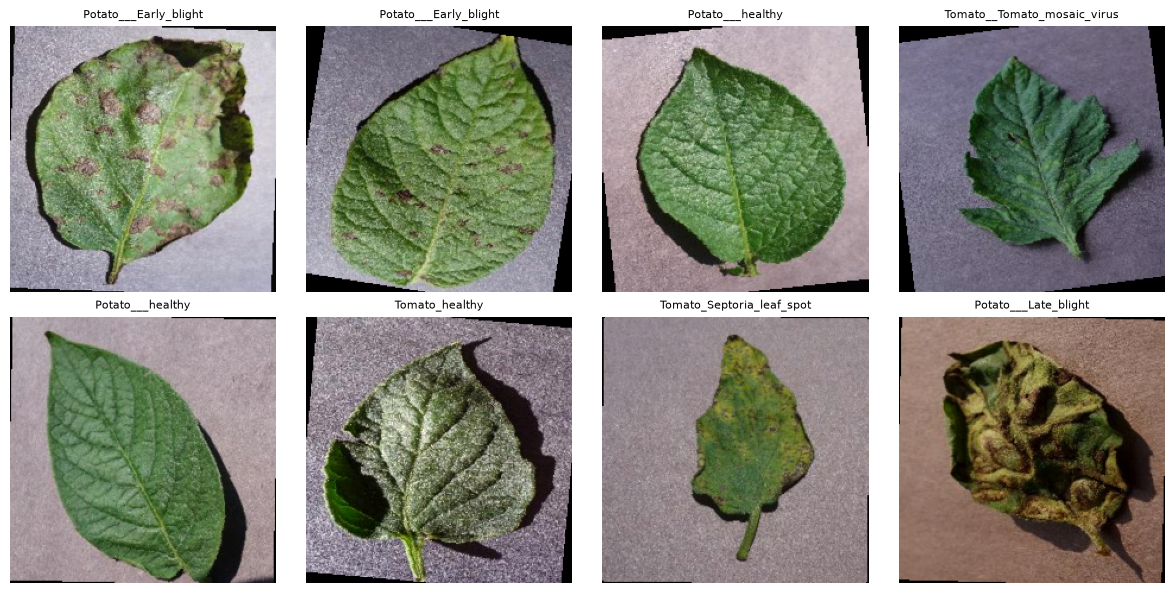

In [5]:
def denormalize(tensor):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    return (tensor.detach().cpu() * std + mean).clamp(0, 1)

images, labels = next(iter(train_loader))
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, img, label in zip(axes.flat, images[:8], labels[:8]):
    ax.imshow(denormalize(img).permute(1, 2, 0))
    ax.set_title(class_names[int(label)], fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 6. Train MobileNetV3-Small

The classifier head is trained first while the feature extractor is frozen. The pretrained ImageNet weights are downloaded by Torchvision if they are not already cached. This requires an internet connection the first time.

In [6]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
weights = models.MobileNet_V3_Small_Weights.DEFAULT
model = models.mobilenet_v3_small(weights=weights)
in_features = model.classifier[-1].in_features
model.classifier[-1] = torch.nn.Linear(in_features, len(class_names))
model = model.to(device)

for parameter in model.features.parameters():
    parameter.requires_grad = False

criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.classifier.parameters(),
                              lr=1e-3, weight_decay=1e-4)

print("Model ready on:", device)
print("Number of output classes:", len(class_names))

Model ready on: cpu
Number of output classes: 15


In [7]:
from tqdm.auto import tqdm

def run_epoch(loader, training=False):
    model.train(training)
    running_loss, correct, total = 0.0, 0, 0
    for xb, yb in tqdm(loader, leave=False):
        xb, yb = xb.to(device), yb.to(device)
        if training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            logits = model(xb)
            loss = criterion(logits, yb)
            if training:
                loss.backward()
                optimizer.step()
        running_loss += loss.item() * len(yb)
        correct += (logits.argmax(1) == yb).sum().item()
        total += len(yb)
    return running_loss / max(total, 1), correct / max(total, 1)

history = []
best_val_acc = -1.0
best_path = MODEL_DIR / "mobilenetv3_plantvillage_best.pth"

for epoch in range(EPOCHS_HEAD):
    train_loss, train_acc = run_epoch(train_loader, training=True)
    val_loss, val_acc = run_epoch(val_loader, training=False)
    history.append({
        "stage": "frozen_head", "epoch": epoch + 1,
        "train_loss": train_loss, "train_accuracy": train_acc,
        "val_loss": val_loss, "val_accuracy": val_acc
    })
    print(f"Epoch {epoch+1}/{EPOCHS_HEAD} | "
          f"train acc={train_acc:.4f} | val acc={val_acc:.4f}")
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save({
            "model_state": model.state_dict(),
            "class_names": class_names,
            "img_size": IMG_SIZE,
            "plant_root": str(PLANT_ROOT),
            "seed": SEED
        }, best_path)

history_df = pd.DataFrame(history)
history_df.to_csv(OUTPUT_DIR / "training_history.csv", index=False)
print("Best validation accuracy:", round(best_val_acc, 4))
print("Checkpoint saved:", best_path)

  0%|          | 0/99 [00:00<?, ?it/s]

  0%|          | 0/22 [00:00<?, ?it/s]

Epoch 1/3 | train acc=0.6000 | val acc=0.6409


  0%|          | 0/99 [00:00<?, ?it/s]

  0%|          | 0/22 [00:00<?, ?it/s]

Epoch 2/3 | train acc=0.7956 | val acc=0.7982


  0%|          | 0/99 [00:00<?, ?it/s]

  0%|          | 0/22 [00:00<?, ?it/s]

Epoch 3/3 | train acc=0.8438 | val acc=0.8249
Best validation accuracy: 0.8249
Checkpoint saved: D:\dsc_1\ML\AgriCropDisease_Research_Project\models\mobilenetv3_plantvillage_best.pth


## 7. Optional fine-tuning

This is disabled by default to keep the first CPU run shorter. Once the initial pipeline works, set `RUN_FINE_TUNING = True` in the configuration cell and rerun the notebook from the beginning if you want this additional stage.

In [8]:
if RUN_FINE_TUNING:
    for parameter in model.features[-3:].parameters():
        parameter.requires_grad = True
    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=1e-5, weight_decay=1e-4
    )
    for epoch in range(EPOCHS_FINE):
        train_loss, train_acc = run_epoch(train_loader, training=True)
        val_loss, val_acc = run_epoch(val_loader, training=False)
        history.append({
            "stage": "fine_tuning", "epoch": epoch + 1,
            "train_loss": train_loss, "train_accuracy": train_acc,
            "val_loss": val_loss, "val_accuracy": val_acc
        })
        print(f"Fine-tune {epoch+1}/{EPOCHS_FINE} | "
              f"train acc={train_acc:.4f} | val acc={val_acc:.4f}")
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save({
                "model_state": model.state_dict(),
                "class_names": class_names,
                "img_size": IMG_SIZE,
                "plant_root": str(PLANT_ROOT),
                "seed": SEED
            }, best_path)
    pd.DataFrame(history).to_csv(OUTPUT_DIR / "training_history.csv", index=False)
else:
    print("Fine-tuning skipped (RUN_FINE_TUNING=False).")

Fine-tuning skipped (RUN_FINE_TUNING=False).


## 8. Evaluate the held-out test set

  0%|          | 0/22 [00:00<?, ?it/s]

Test accuracy: 0.8669
Macro precision: 0.8845
Macro recall: 0.8664
Macro F1: 0.8665

Per-class report:


,precision,recall,f1-score,support
Pepper__bell___Bacterial_spot,0.846154,1.000000,0.916667,22.000000
Pepper__bell___healthy,1.000000,0.956522,0.977778,23.000000
Potato___Early_blight,0.913043,0.954545,0.933333,22.000000
Potato___Late_blight,0.793103,1.000000,0.884615,23.000000
Potato___healthy,1.000000,0.869565,0.930233,23.000000
Tomato_Bacterial_spot,0.791667,0.863636,0.826087,22.000000
Tomato_Early_blight,0.894737,0.739130,0.809524,23.000000
Tomato_Late_blight,0.760000,0.826087,0.791667,23.000000
Tomato_Leaf_Mold,1.000000,0.727273,0.842105,22.000000
Tomato_Septoria_leaf_spot,0.933333,0.636364,0.756757,22.000000


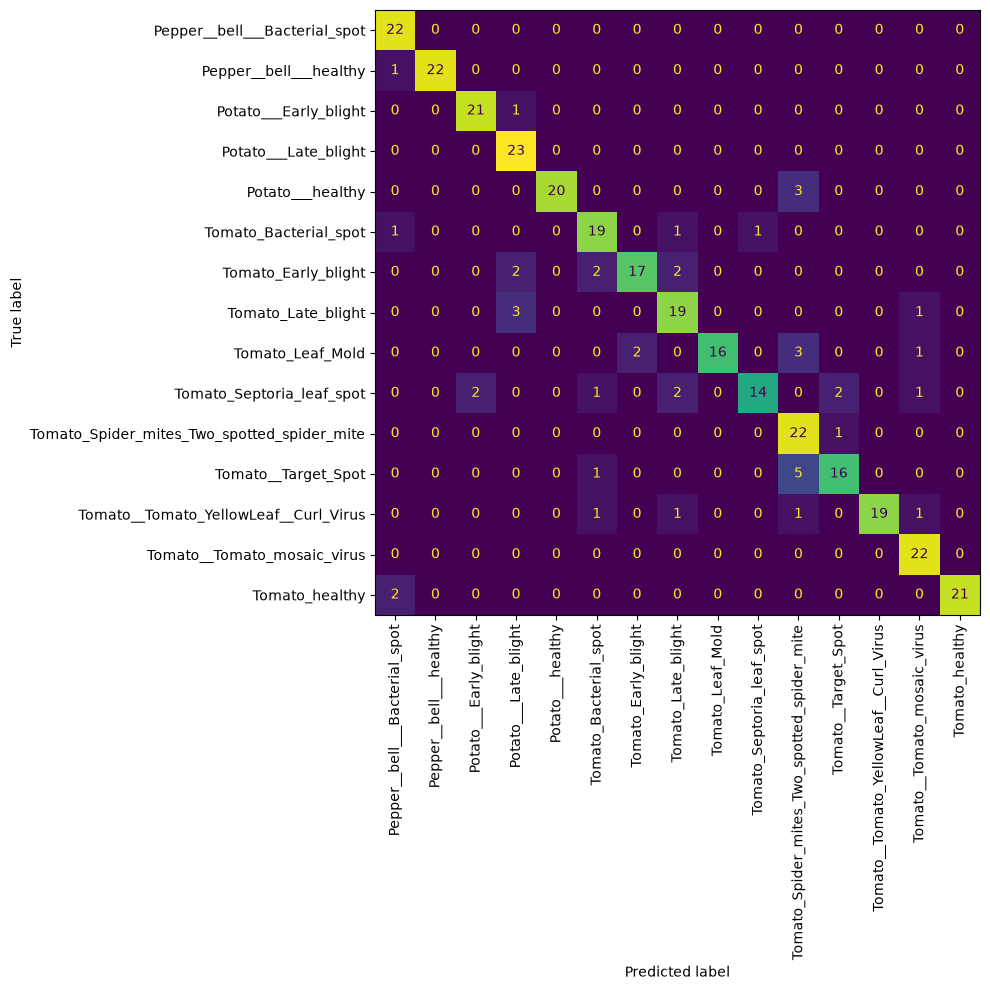

In [9]:
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, f1_score, precision_score, recall_score
)

checkpoint = torch.load(best_path, map_location=device, weights_only=True)
model.load_state_dict(checkpoint["model_state"])
model.eval()

all_y, all_pred = [], []
with torch.no_grad():
    for xb, yb in tqdm(test_loader):
        predictions = model(xb.to(device)).argmax(1).cpu().numpy()
        all_pred.extend(predictions.tolist())
        all_y.extend(yb.numpy().tolist())

test_accuracy = accuracy_score(all_y, all_pred)
macro_precision = precision_score(all_y, all_pred, average="macro", zero_division=0)
macro_recall = recall_score(all_y, all_pred, average="macro", zero_division=0)
macro_f1 = f1_score(all_y, all_pred, average="macro", zero_division=0)

print("Test accuracy:", round(test_accuracy, 4))
print("Macro precision:", round(macro_precision, 4))
print("Macro recall:", round(macro_recall, 4))
print("Macro F1:", round(macro_f1, 4))
print("\nPer-class report:")
report = classification_report(all_y, all_pred, target_names=class_names,
                               output_dict=True, zero_division=0)
display(pd.DataFrame(report).T)
pd.DataFrame(report).T.to_csv(OUTPUT_DIR / "classification_report.csv")

cm = confusion_matrix(all_y, all_pred)
fig, ax = plt.subplots(figsize=(12, 10))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
    ax=ax, xticks_rotation=90, colorbar=False
)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=180, bbox_inches="tight")
plt.show()

metrics = {
    "test_accuracy": float(test_accuracy),
    "macro_precision": float(macro_precision),
    "macro_recall": float(macro_recall),
    "macro_f1": float(macro_f1),
    "test_images": int(len(all_y)),
    "classes": class_names
}
with open(OUTPUT_DIR / "test_metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)

## 9. Predict one image

Example image: D:\dsc_1\ML\MyDrive\CropDiseaseProject\datasets\PlantVillage\PlantVillage\Tomato_Early_blight\ac57ab70-6d8c-4065-8bab-3a88b5239aea___RS_Erly.B 7408.JPG


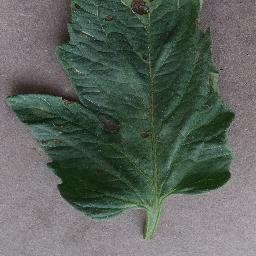

,predicted_class,probability
0,Tomato_Bacterial_spot,0.837084
1,Tomato_Early_blight,0.139602
2,Tomato__Target_Spot,0.010018
3,Tomato_Spider_mites_Two_spotted_spider_mite,0.007100
4,Tomato__Tomato_YellowLeaf__Curl_Virus,0.002054


In [10]:
def predict_image(image_path, top_k=5, show_image=True):
    image_path = Path(image_path)
    if not image_path.exists():
        raise FileNotFoundError(image_path)
    img = Image.open(image_path).convert("RGB")
    x = eval_tfms(img).unsqueeze(0).to(device)
    model.eval()
    with torch.no_grad():
        probabilities = torch.softmax(model(x), dim=1)[0].cpu().numpy()
    order = np.argsort(probabilities)[::-1][:top_k]
    result = pd.DataFrame({
        "predicted_class": [class_names[i] for i in order],
        "probability": [float(probabilities[i]) for i in order]
    })
    if show_image:
        display(img)
    display(result)
    return result

# Automatically select one image from the held-out test subset.
sample_index = int(test_idx[0])
sample_path = Path(base_ds.samples[sample_index][0])
print("Example image:", sample_path)
sample_prediction = predict_image(sample_path)

## 10. Grad-CAM explanation

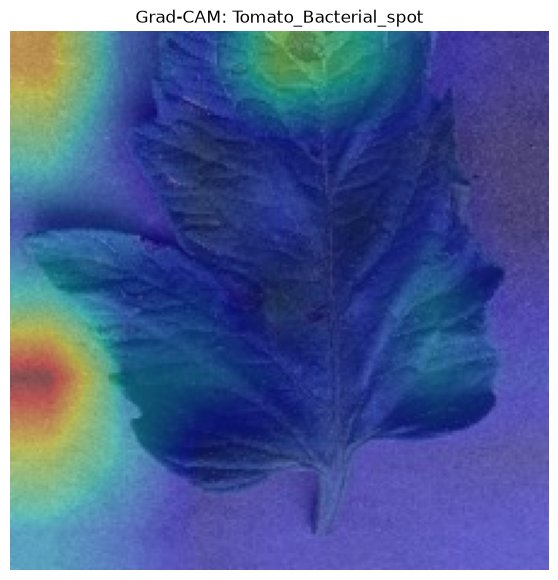

('Tomato_Bacterial_spot',
 array([[0.7280194 , 0.7280194 , 0.7280194 , ..., 0.05982724, 0.05982724,
         0.05982724],
        [0.7280194 , 0.7280194 , 0.7280194 , ..., 0.05982724, 0.05982724,
         0.05982724],
        [0.7280194 , 0.7280194 , 0.7280194 , ..., 0.05982724, 0.05982724,
         0.05982724],
        ...,
        [0.31131703, 0.31131703, 0.31131703, ..., 0.12959804, 0.12959804,
         0.12959804],
        [0.31131703, 0.31131703, 0.31131703, ..., 0.12959804, 0.12959804,
         0.12959804],
        [0.31131703, 0.31131703, 0.31131703, ..., 0.12959804, 0.12959804,
         0.12959804]], shape=(224, 224), dtype=float32))

In [11]:

def gradcam(image_path):
    img = Image.open(image_path).convert("RGB")
    x = eval_tfms(img).unsqueeze(0).to(device)

    # Enable gradients even when the backbone is frozen
    x.requires_grad_(True)

    activations = []
    gradients = []

    target_layer = model.features[-1]

    # Capture feature maps and their gradients
    def forward_hook(module, inputs, output):
        activations.append(output)
        output.register_hook(
            lambda grad: gradients.append(grad)
        )

    handle = target_layer.register_forward_hook(forward_hook)

    try:
        model.eval()
        model.zero_grad(set_to_none=True)

        with torch.enable_grad():
            logits = model(x)
            predicted_index = int(logits.argmax(1).item())

            logits[0, predicted_index].backward()

        if not activations or not gradients:
            raise RuntimeError(
                "Grad-CAM could not capture activations or gradients."
            )

        acts = activations[0].detach()
        grads = gradients[0].detach()

        weights = grads.mean(dim=(2, 3), keepdim=True)

        cam = torch.relu(
            (weights * acts).sum(dim=1, keepdim=True)
        )

        cam = torch.nn.functional.interpolate(
            cam,
            size=(IMG_SIZE, IMG_SIZE),
            mode="bilinear",
            align_corners=False
        )[0, 0].cpu().numpy()

        cam = (cam - cam.min()) / (
            cam.max() - cam.min() + 1e-8
        )

        base_img = np.asarray(
            img.resize((IMG_SIZE, IMG_SIZE))
        ).astype(np.float32) / 255.0

        fig, ax = plt.subplots(figsize=(7, 7))
        ax.imshow(base_img)
        ax.imshow(cam, alpha=0.40, cmap="jet")

        ax.set_title(
            "Grad-CAM: " + class_names[predicted_index]
        )
        ax.axis("off")
        plt.show()

        return class_names[predicted_index], cam

    finally:
        handle.remove()


gradcam(sample_path)


## 11. Local evidence base and TF-IDF retrieval (RAG)

This section creates an **empty template** if you have not added sources yet. Add verified records from official agricultural extension publications, government plant-health services, or peer-reviewed papers before using retrieval. The notebook will not invent sources or management advice.

Required CSV columns: `crop`, `disease_or_topic`, `symptoms`, `management`, `source_title`, `source_url`, `source_year`.

In [12]:
KB_PATH = KB_DIR / "knowledge_base.csv"
required_kb_columns = [
    "crop", "disease_or_topic", "symptoms", "management",
    "source_title", "source_url", "source_year"
]
if not KB_PATH.exists():
    pd.DataFrame(columns=required_kb_columns).to_csv(KB_PATH, index=False)

knowledge_base = pd.read_csv(KB_PATH).fillna("")
print("Knowledge base file:", KB_PATH)
print("Records currently available:", len(knowledge_base))
display(knowledge_base.head())

Knowledge base file: D:\dsc_1\ML\AgriCropDisease_Research_Project\knowledge_base\knowledge_base.csv
Records currently available: 5


,crop,disease_or_topic,symptoms,management,source_title,source_url,source_year
0,Tomato,Early blight,Brown spots with concentric rings and yellow m...,Remove and destroy infected crop debris. Pract...,TNAU Agritech Portal - Tomato Early Blight,https://agritech.tnau.ac.in/crop_protection/to...,2023
1,Tomato,Late blight,Water-soaked black lesions on leaves and stems...,Maintain proper drainage and practice crop rot...,TNAU Agritech Portal - Tomato Late Blight,https://agritech.tnau.ac.in/crop_protection/to...,2023
2,Tomato,Bacterial leaf spot,Small brown water-soaked circular spots with y...,Use disease-free seeds and remove infected pla...,TNAU Agritech Portal - Tomato Bacterial Leaf Spot,https://agritech.tnau.ac.in/crop_protection/to...,2023
3,Potato,Late blight,Water-soaked leaf spots that become purple-bro...,"Use healthy seed tubers, avoid tuber injuries ...",TNAU Agritech Portal - Potato Late Blight,https://agritech.tnau.ac.in/crop_protection/cr...,2023
4,Potato,Early blight,Brown-black angular or oval leaf spots with ch...,Use disease-free seed tubers and remove and de...,TNAU Agritech Portal - Potato Early Blight,https://agritech.tnau.ac.in/crop_protection/cr...,2023


In [13]:

import pandas as pd
from pathlib import Path

KB_PATH = KB_DIR / "knowledge_base.csv"

records = [
    {
        "crop": "Tomato",
        "disease_or_topic": "Early blight",
        "symptoms": "Brown spots with concentric rings and yellow margins on leaves. Fruit may develop brown concentric rings.",
        "management": "Remove and destroy infected crop debris. Practice crop rotation and use disease-free seeds.",
        "source_title": "TNAU Agritech Portal - Tomato Early Blight",
        "source_url": "https://agritech.tnau.ac.in/crop_protection/tomato_diseases_2.html",
        "source_year": "2023"
    },
    {
        "crop": "Tomato",
        "disease_or_topic": "Late blight",
        "symptoms": "Water-soaked black lesions on leaves and stems, rapidly expanding necrosis, and white growth on affected leaves.",
        "management": "Maintain proper drainage and practice crop rotation. Remove infected crop debris.",
        "source_title": "TNAU Agritech Portal - Tomato Late Blight",
        "source_url": "https://agritech.tnau.ac.in/crop_protection/tomato_diseases_8.html",
        "source_year": "2023"
    },
    {
        "crop": "Tomato",
        "disease_or_topic": "Bacterial leaf spot",
        "symptoms": "Small brown water-soaked circular spots with yellow halos on leaves. Older leaves may drop.",
        "management": "Use disease-free seeds and remove infected plant debris. Avoid practices that spread contaminated water between plants.",
        "source_title": "TNAU Agritech Portal - Tomato Bacterial Leaf Spot",
        "source_url": "https://agritech.tnau.ac.in/crop_protection/tomato_diseases_11.html",
        "source_year": "2023"
    },
    {
        "crop": "Potato",
        "disease_or_topic": "Late blight",
        "symptoms": "Water-soaked leaf spots that become purple-brown or black, with white growth underneath leaves. Stems and tubers may also be affected.",
        "management": "Use healthy seed tubers, avoid tuber injuries during harvesting, and remove infected plant material.",
        "source_title": "TNAU Agritech Portal - Potato Late Blight",
        "source_url": "https://agritech.tnau.ac.in/crop_protection/crop_prot_crop%20diseases_veg_potato_1.html",
        "source_year": "2023"
    },
    {
        "crop": "Potato",
        "disease_or_topic": "Early blight",
        "symptoms": "Brown-black angular or oval leaf spots with characteristic concentric rings. Several spots may merge.",
        "management": "Use disease-free seed tubers and remove and destroy infected plant debris.",
        "source_title": "TNAU Agritech Portal - Potato Early Blight",
        "source_url": "https://agritech.tnau.ac.in/crop_protection/crop_prot_crop%20diseases_veg_potato_2.html",
        "source_year": "2023"
    }
]

new_records = pd.DataFrame(records)

# Add to existing records without deleting them
if KB_PATH.exists():
    old_records = pd.read_csv(KB_PATH).fillna("")
    knowledge_base = pd.concat(
        [old_records, new_records],
        ignore_index=True
    )
    knowledge_base = knowledge_base.drop_duplicates(
        subset=["crop", "disease_or_topic", "source_url"]
    )
else:
    knowledge_base = new_records

knowledge_base.to_csv(KB_PATH, index=False)

print("Knowledge base saved:", KB_PATH)
print("Total evidence records:", len(knowledge_base))

display(knowledge_base)


Knowledge base saved: D:\dsc_1\ML\AgriCropDisease_Research_Project\knowledge_base\knowledge_base.csv
Total evidence records: 5


,crop,disease_or_topic,symptoms,management,source_title,source_url,source_year
0,Tomato,Early blight,Brown spots with concentric rings and yellow m...,Remove and destroy infected crop debris. Pract...,TNAU Agritech Portal - Tomato Early Blight,https://agritech.tnau.ac.in/crop_protection/to...,2023
1,Tomato,Late blight,Water-soaked black lesions on leaves and stems...,Maintain proper drainage and practice crop rot...,TNAU Agritech Portal - Tomato Late Blight,https://agritech.tnau.ac.in/crop_protection/to...,2023
2,Tomato,Bacterial leaf spot,Small brown water-soaked circular spots with y...,Use disease-free seeds and remove infected pla...,TNAU Agritech Portal - Tomato Bacterial Leaf Spot,https://agritech.tnau.ac.in/crop_protection/to...,2023
3,Potato,Late blight,Water-soaked leaf spots that become purple-bro...,"Use healthy seed tubers, avoid tuber injuries ...",TNAU Agritech Portal - Potato Late Blight,https://agritech.tnau.ac.in/crop_protection/cr...,2023
4,Potato,Early blight,Brown-black angular or oval leaf spots with ch...,Use disease-free seed tubers and remove and de...,TNAU Agritech Portal - Potato Early Blight,https://agritech.tnau.ac.in/crop_protection/cr...,2023


In [14]:

# Rebuild the TF-IDF retrieval system using the populated knowledge base

knowledge_base = pd.read_csv(KB_PATH).fillna("")

def retrieve_evidence(question, top_k=3):
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.metrics.pairwise import cosine_similarity

    text_fields = [
        "crop", "disease_or_topic", "symptoms", "management"
    ]

    documents = knowledge_base[text_fields].astype(str).agg(
        " ".join, axis=1
    ).tolist()

    vectorizer = TfidfVectorizer(
        stop_words="english",
        ngram_range=(1, 2)
    )

    matrix = vectorizer.fit_transform(documents)
    query_vector = vectorizer.transform([question])

    scores = cosine_similarity(query_vector, matrix)[0]
    order = scores.argsort()[::-1][:top_k]

    results = knowledge_base.iloc[order].copy()
    results.insert(0, "similarity", scores[order])

    return results[results["similarity"] > 0].reset_index(drop=True)


def answer_with_evidence(question, top_k=3):
    results = retrieve_evidence(question, top_k)

    if results.empty:
        print("No matching source-backed evidence found.")
        return results

    display(results[[
        "similarity",
        "crop",
        "disease_or_topic",
        "symptoms",
        "management",
        "source_title",
        "source_url"
    ]])

    return results


answer_with_evidence(
    "What are the symptoms and management of tomato early blight?"
)


,similarity,crop,disease_or_topic,symptoms,management,source_title,source_url
0,0.271129,Tomato,Early blight,Brown spots with concentric rings and yellow m...,Remove and destroy infected crop debris. Pract...,TNAU Agritech Portal - Tomato Early Blight,https://agritech.tnau.ac.in/crop_protection/to...
1,0.163437,Potato,Early blight,Brown-black angular or oval leaf spots with ch...,Use disease-free seed tubers and remove and de...,TNAU Agritech Portal - Potato Early Blight,https://agritech.tnau.ac.in/crop_protection/cr...
2,0.069651,Tomato,Late blight,Water-soaked black lesions on leaves and stems...,Maintain proper drainage and practice crop rot...,TNAU Agritech Portal - Tomato Late Blight,https://agritech.tnau.ac.in/crop_protection/to...


,similarity,crop,disease_or_topic,symptoms,management,source_title,source_url,source_year
0,0.271129,Tomato,Early blight,Brown spots with concentric rings and yellow m...,Remove and destroy infected crop debris. Pract...,TNAU Agritech Portal - Tomato Early Blight,https://agritech.tnau.ac.in/crop_protection/to...,2023
1,0.163437,Potato,Early blight,Brown-black angular or oval leaf spots with ch...,Use disease-free seed tubers and remove and de...,TNAU Agritech Portal - Potato Early Blight,https://agritech.tnau.ac.in/crop_protection/cr...,2023
2,0.069651,Tomato,Late blight,Water-soaked black lesions on leaves and stems...,Maintain proper drainage and practice crop rot...,TNAU Agritech Portal - Tomato Late Blight,https://agritech.tnau.ac.in/crop_protection/to...,2023


In [15]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

def retrieve_evidence(question, top_k=3):
    frame = pd.read_csv(KB_PATH).fillna("")
    missing = [c for c in required_kb_columns if c not in frame.columns]
    if missing:
        raise ValueError(f"Knowledge base is missing columns: {missing}")
    if frame.empty:
        print("No trusted evidence records have been added yet.")
        return frame

    text_fields = ["crop", "disease_or_topic", "symptoms", "management"]
    documents = frame[text_fields].astype(str).agg(" ".join, axis=1).tolist()
    vectorizer = TfidfVectorizer(stop_words="english", ngram_range=(1, 2))
    matrix = vectorizer.fit_transform(documents)
    query_vector = vectorizer.transform([question])
    scores = cosine_similarity(query_vector, matrix)[0]
    order = np.argsort(scores)[::-1][:top_k]
    result = frame.iloc[order].copy()
    result.insert(0, "similarity", scores[order])
    return result[result["similarity"] > 0].reset_index(drop=True)

def answer_with_evidence(question, top_k=3):
    hits = retrieve_evidence(question, top_k=top_k)
    if hits.empty:
        print("No matching source-backed evidence found. Do not infer treatment.")
        return hits
    display(hits[["similarity", "crop", "disease_or_topic", "symptoms",
                  "management", "source_title", "source_year", "source_url"]])
    return hits

# Example after adding trusted records to the CSV:
# answer_with_evidence("tomato early blight symptoms and management")

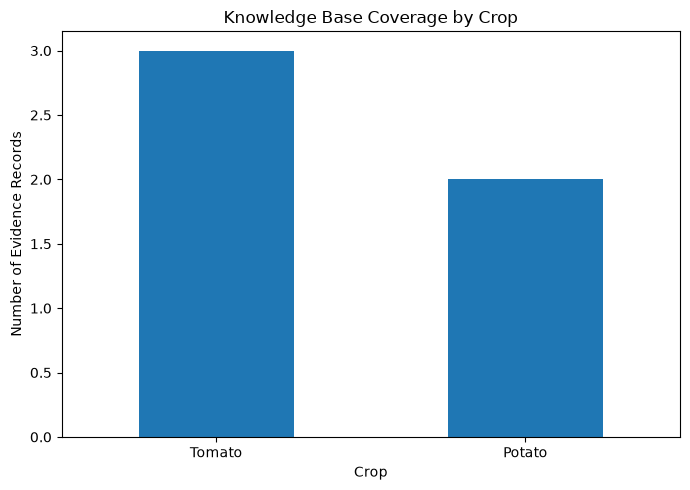

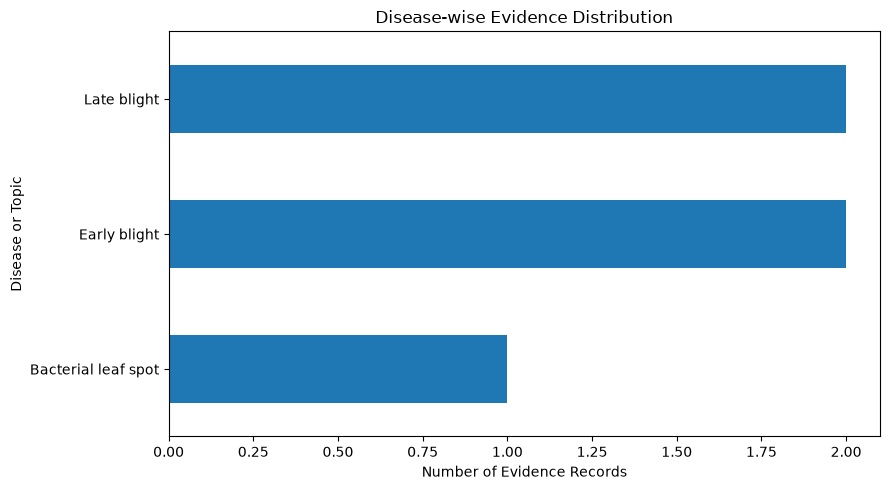

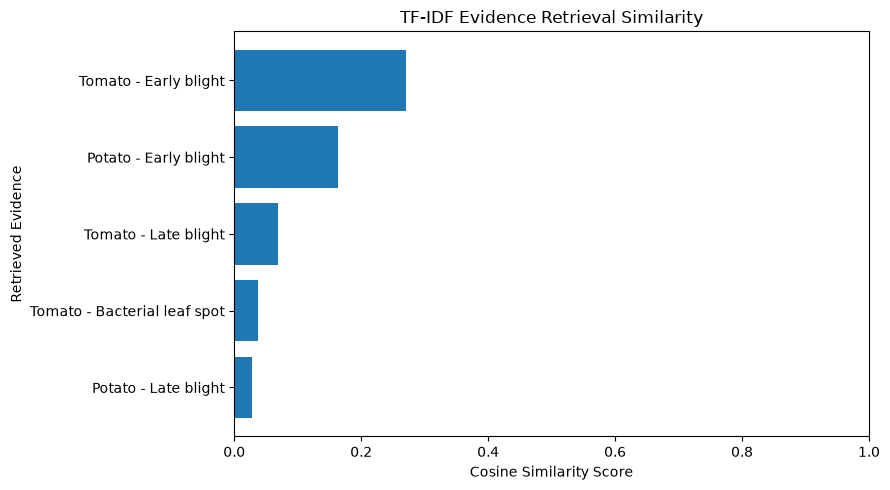

TF-IDF visualizations saved in: D:\dsc_1\ML\AgriCropDisease_Research_Project\figures


In [16]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Output folder
FIGURE_DIR = PROJECT_ROOT / "AgriCropDisease_Research_Project" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Load knowledge base
kb = pd.read_csv(KB_PATH).fillna("")

# -----------------------------------------
# 1. Knowledge base records by crop
# -----------------------------------------
crop_counts = kb["crop"].value_counts()

plt.figure(figsize=(7, 5))
crop_counts.plot(kind="bar")
plt.title("Knowledge Base Coverage by Crop")
plt.xlabel("Crop")
plt.ylabel("Number of Evidence Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "kb_records_by_crop.png", dpi=300)
plt.show()


# -----------------------------------------
# 2. Knowledge base records by disease
# -----------------------------------------
disease_counts = kb["disease_or_topic"].value_counts()

plt.figure(figsize=(9, 5))
disease_counts.sort_values().plot(kind="barh")
plt.title("Disease-wise Evidence Distribution")
plt.xlabel("Number of Evidence Records")
plt.ylabel("Disease or Topic")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "kb_disease_distribution.png", dpi=300)
plt.show()


# -----------------------------------------
# 3. TF-IDF similarity score visualization
# -----------------------------------------
query = "tomato early blight symptoms and management"
retrieved = retrieve_evidence(query, top_k=5)

if not retrieved.empty:
    labels = (
        retrieved["crop"].astype(str)
        + " - "
        + retrieved["disease_or_topic"].astype(str)
    )

    plt.figure(figsize=(9, 5))
    plt.barh(labels[::-1], retrieved["similarity"].values[::-1])
    plt.title("TF-IDF Evidence Retrieval Similarity")
    plt.xlabel("Cosine Similarity Score")
    plt.ylabel("Retrieved Evidence")
    plt.xlim(0, 1)
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / "tfidf_similarity_scores.png", dpi=300)
    plt.show()
else:
    print("No matching evidence found for the selected query.")

print("TF-IDF visualizations saved in:", FIGURE_DIR)


In [17]:

from pathlib import Path
import pandas as pd

print("CHECKING EXTERNAL DATASETS\n")

for name, root in [
    ("Plant Disease Recognition", PDR_ROOT),
    ("Cassava", CASSAVA_ROOT),
    ("PlantDoc", DATASETS_ROOT / "PlantDoc")
]:
    print("\n", name)
    print("Path:", root)
    print("Exists:", root.exists())

    if root.exists():
        folders = [
            p for p in root.iterdir()
            if p.is_dir()
        ]

        print("Subfolders:")
        for folder in folders:
            count = sum(
                1 for f in folder.rglob("*")
                if f.is_file() and f.suffix.lower()
                in IMAGE_EXTS
            )
            print(f"  {folder.name}: {count} images")

        csv_files = list(root.glob("*.csv"))
        print("CSV files:", [f.name for f in csv_files])


CHECKING EXTERNAL DATASETS


 Plant Disease Recognition
Path: D:\dsc_1\ML\MyDrive\CropDiseaseProject\datasets\Plant Disease Recognition
Exists: True
Subfolders:
  Train: 1322 images
  Validation: 60 images
CSV files: []

 Cassava
Path: D:\dsc_1\ML\MyDrive\CropDiseaseProject\datasets\Cassava Leaf Disease
Exists: True
Subfolders:
  test_images: 1 images
  test_tfrecords: 0 images
  train_images: 21397 images
  train_tfrecords: 0 images
CSV files: ['sample_submission.csv', 'train.csv']

 PlantDoc
Path: D:\dsc_1\ML\MyDrive\CropDiseaseProject\datasets\PlantDoc
Exists: True
Subfolders:
CSV files: []


In [18]:
from pathlib import Path

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

PDR_ROOT = DATASETS_ROOT / "Plant Disease Recognition"

for split_name in ["Train", "Validation"]:
    split_path = PDR_ROOT / split_name

    print(f"\n{'='*60}")
    print(f"{split_name.upper()} DATASET")
    print(f"{'='*60}")

    if not split_path.exists():
        print("Folder not found:", split_path)
        continue

    total_images = 0

    for class_folder in sorted(p for p in split_path.iterdir() if p.is_dir()):
        image_files = [
            f for f in class_folder.rglob("*")
            if f.is_file() and f.suffix.lower() in IMAGE_EXTS
        ]

        count = len(image_files)
        total_images += count
        print(f"{class_folder.name}: {count} images")

    print("Total images:", total_images)


TRAIN DATASET
Train: 1322 images
Total images: 1322

VALIDATION DATASET
Validation: 60 images
Total images: 60


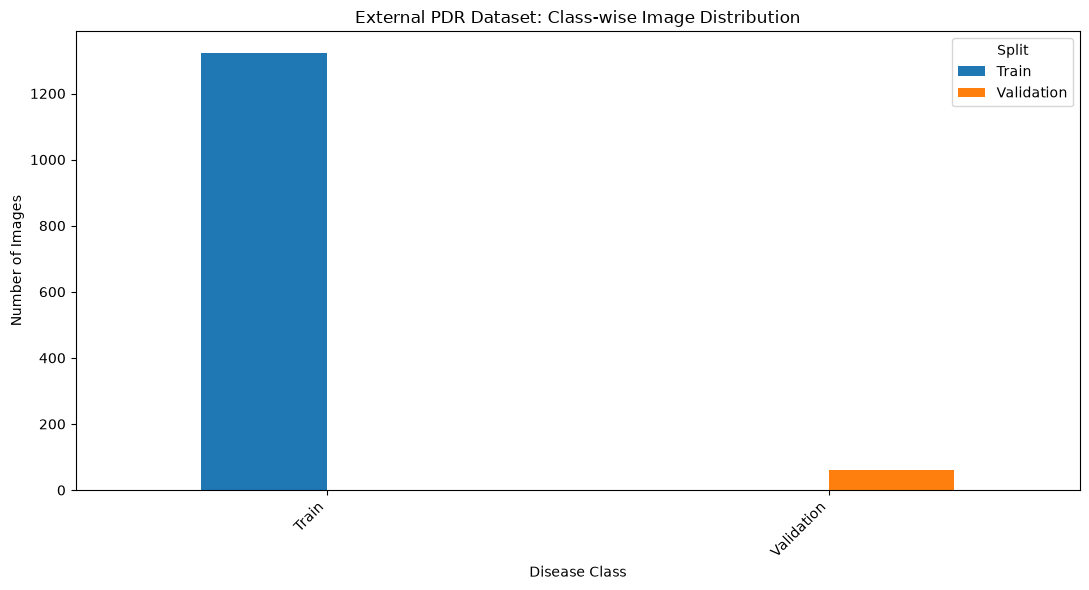

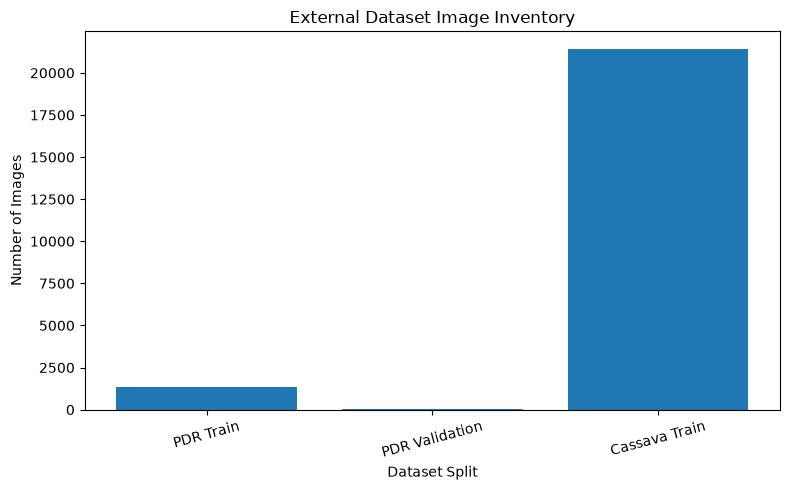


PDR class distribution:


,Split,Class,Images
0,Train,Train,1322
1,Validation,Validation,60



External dataset inventory:


,Dataset Split,Images
0,PDR Train,1322
1,PDR Validation,60
2,Cassava Train,21397



All figures saved in: D:\dsc_1\ML\AgriCropDisease_Research_Project\figures


In [19]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

PDR_ROOT = DATASETS_ROOT / "Plant Disease Recognition"
CASSAVA_ROOT = DATASETS_ROOT / "Cassava Leaf Disease"

# -----------------------------------------
# 1. Count PDR images by class and split
# -----------------------------------------
pdr_records = []

for split in ["Train", "Validation"]:
    split_path = PDR_ROOT / split

    if not split_path.exists():
        continue

    class_folders = [
        p for p in split_path.iterdir() if p.is_dir()
    ]

    for class_folder in sorted(class_folders):
        count = sum(
            1 for f in class_folder.rglob("*")
            if f.is_file() and f.suffix.lower() in IMAGE_EXTS
        )

        pdr_records.append({
            "Split": split,
            "Class": class_folder.name,
            "Images": count
        })

pdr_df = pd.DataFrame(pdr_records)

if not pdr_df.empty:
    pdr_pivot = pdr_df.pivot_table(
        index="Class",
        columns="Split",
        values="Images",
        aggfunc="sum",
        fill_value=0
    )

    ax = pdr_pivot.plot(
        kind="bar",
        figsize=(11, 6)
    )

    ax.set_title("External PDR Dataset: Class-wise Image Distribution")
    ax.set_xlabel("Disease Class")
    ax.set_ylabel("Number of Images")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.savefig(
        FIGURE_DIR / "pdr_class_distribution.png",
        dpi=300
    )
    plt.show()

else:
    print("No class subfolders detected inside PDR Train/Validation.")


# -----------------------------------------
# 2. External dataset split inventory
# -----------------------------------------
def count_images(folder):
    if not folder.exists():
        return 0

    return sum(
        1 for f in folder.rglob("*")
        if f.is_file() and f.suffix.lower() in IMAGE_EXTS
    )

inventory = {
    "PDR Train": count_images(PDR_ROOT / "Train"),
    "PDR Validation": count_images(PDR_ROOT / "Validation"),
    "Cassava Train": count_images(CASSAVA_ROOT / "train_images")
}

inventory_df = pd.DataFrame(
    list(inventory.items()),
    columns=["Dataset Split", "Images"]
)

plt.figure(figsize=(8, 5))
plt.bar(inventory_df["Dataset Split"], inventory_df["Images"])
plt.title("External Dataset Image Inventory")
plt.xlabel("Dataset Split")
plt.ylabel("Number of Images")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "external_dataset_inventory.png",
    dpi=300
)
plt.show()

print("\nPDR class distribution:")
display(pdr_df)

print("\nExternal dataset inventory:")
display(inventory_df)

print("\nAll figures saved in:", FIGURE_DIR)


In [20]:

# Display PDR class names and image counts
print("PDR EXTERNAL DATASET CLASS SUMMARY")
print("=" * 60)

display(
    pdr_df.sort_values(["Class", "Split"]).reset_index(drop=True)
)

pdr_classes = sorted(pdr_df["Class"].unique().tolist())

print("\nPDR classes detected:")
for name in pdr_classes:
    print("-", name)

print("\nNumber of PDR classes:", len(pdr_classes))

# Display the original model's class names
print("\nPLANTVILLAGE MODEL CLASSES")
print("=" * 60)

for index, name in enumerate(class_names):
    print(index, ":", name)

print("\nNumber of model classes:", len(class_names))


PDR EXTERNAL DATASET CLASS SUMMARY


,Split,Class,Images
0,Train,Train,1322
1,Validation,Validation,60



PDR classes detected:
- Train
- Validation

Number of PDR classes: 2

PLANTVILLAGE MODEL CLASSES
0 : Pepper__bell___Bacterial_spot
1 : Pepper__bell___healthy
2 : Potato___Early_blight
3 : Potato___Late_blight
4 : Potato___healthy
5 : Tomato_Bacterial_spot
6 : Tomato_Early_blight
7 : Tomato_Late_blight
8 : Tomato_Leaf_Mold
9 : Tomato_Septoria_leaf_spot
10 : Tomato_Spider_mites_Two_spotted_spider_mite
11 : Tomato__Target_Spot
12 : Tomato__Tomato_YellowLeaf__Curl_Virus
13 : Tomato__Tomato_mosaic_virus
14 : Tomato_healthy

Number of model classes: 15


In [21]:

from pathlib import Path

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

PDR_ROOT = DATASETS_ROOT / "Plant Disease Recognition"

for split in ["Train", "Validation"]:
    split_path = PDR_ROOT / split

    print("\n" + "=" * 65)
    print("SPLIT:", split)
    print("=" * 65)

    if not split_path.exists():
        print("Missing folder:", split_path)
        continue

    for item in sorted(split_path.iterdir()):
        if item.is_dir():
            count = sum(
                1 for f in item.rglob("*")
                if f.is_file() and f.suffix.lower() in IMAGE_EXTS
            )
            print(f"CLASS FOLDER: {item.name} | IMAGES: {count}")

        elif item.is_file():
            print("FILE:", item.name)



SPLIT: Train
CLASS FOLDER: Train | IMAGES: 1322

SPLIT: Validation
CLASS FOLDER: Validation | IMAGES: 60


In [22]:

from pathlib import Path

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for split in ["Train", "Validation"]:
    root = PDR_ROOT / split / split

    print("\n" + "=" * 60)
    print(f"{split.upper()} NESTED STRUCTURE")
    print("=" * 60)
    print("Path:", root)
    print("Exists:", root.exists())

    if not root.exists():
        continue

    # Show folders and image counts at every level
    for folder in sorted([root] + [
        p for p in root.rglob("*") if p.is_dir()
    ]):
        depth = len(folder.relative_to(root).parts)
        if depth > 3:
            continue

        images = [
            f for f in folder.iterdir()
            if f.is_file() and f.suffix.lower() in IMAGE_EXTS
        ]

        indent = "    " * depth
        print(f"{indent}{folder.name}/  ({len(images)} direct images)")

    # Show a few image paths
    all_images = [
        f for f in root.rglob("*")
        if f.is_file() and f.suffix.lower() in IMAGE_EXTS
    ]

    print("\nTotal images:", len(all_images))
    print("Sample image paths:")
    for image_path in all_images[:5]:
        print(image_path)



TRAIN NESTED STRUCTURE
Path: D:\dsc_1\ML\MyDrive\CropDiseaseProject\datasets\Plant Disease Recognition\Train\Train
Exists: True
Train/  (0 direct images)
    Healthy/  (458 direct images)
    Powdery/  (430 direct images)
    Rust/  (434 direct images)

Total images: 1322
Sample image paths:
D:\dsc_1\ML\MyDrive\CropDiseaseProject\datasets\Plant Disease Recognition\Train\Train\Healthy\800edef467d27c15.jpg
D:\dsc_1\ML\MyDrive\CropDiseaseProject\datasets\Plant Disease Recognition\Train\Train\Healthy\801d6dcd96e48ebc.jpg
D:\dsc_1\ML\MyDrive\CropDiseaseProject\datasets\Plant Disease Recognition\Train\Train\Healthy\802b59956a7aa5e7.jpg
D:\dsc_1\ML\MyDrive\CropDiseaseProject\datasets\Plant Disease Recognition\Train\Train\Healthy\803bcb65f486e39a.jpg
D:\dsc_1\ML\MyDrive\CropDiseaseProject\datasets\Plant Disease Recognition\Train\Train\Healthy\803e60cf3c64e1fe.jpg

VALIDATION NESTED STRUCTURE
Path: D:\dsc_1\ML\MyDrive\CropDiseaseProject\datasets\Plant Disease Recognition\Validation\Validation


In [23]:

import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader

# -----------------------------------------
# 1. Paths and output folders
# -----------------------------------------
PDR_VAL_ROOT = PDR_ROOT / "Validation" / "Validation"

FIGURE_DIR = PROJECT_ROOT / "AgriCropDisease_Research_Project" / "figures"
REPORT_DIR = PROJECT_ROOT / "AgriCropDisease_Research_Project" / "reports"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

CHECKPOINT_PATH = (
    PROJECT_ROOT
    / "AgriCropDisease_Research_Project"
    / "models"
    / "mobilenetv3_plantvillage_best.pth"
)

# -----------------------------------------
# 2. Restore the saved MobileNetV3 model
# -----------------------------------------
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

model_class_names = checkpoint["class_names"]

model = models.mobilenet_v3_small(weights=None)
in_features = model.classifier[-1].in_features
model.classifier[-1] = torch.nn.Linear(
    in_features, len(model_class_names)
)

model.load_state_dict(checkpoint["model_state"])
model = model.to(device)
model.eval()

print("Saved MobileNetV3 checkpoint loaded.")
print("Model classes:", len(model_class_names))

# -----------------------------------------
# 3. Load PDR validation images
# -----------------------------------------
pdr_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

pdr_dataset = datasets.ImageFolder(
    str(PDR_VAL_ROOT),
    transform=pdr_transform
)

pdr_loader = DataLoader(
    pdr_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

print("\nPDR validation classes:", pdr_dataset.classes)
print("Validation images:", len(pdr_dataset))

# -----------------------------------------
# 4. Generate predictions
# -----------------------------------------
results = []
softmax = torch.nn.Softmax(dim=1)

with torch.no_grad():
    for images, labels in pdr_loader:
        images = images.to(device)

        logits = model(images)
        probabilities = softmax(logits)

        confidence, predictions = probabilities.max(dim=1)
        top_values, top_indices = probabilities.topk(
            k=3, dim=1
        )

        for i in range(len(labels)):
            actual_class = pdr_dataset.classes[labels[i].item()]
            predicted_class = model_class_names[
                predictions[i].item()
            ]

            results.append({
                "actual_pdr_class": actual_class,
                "predicted_pv_class": predicted_class,
                "confidence": confidence[i].item(),
                "top2_class": model_class_names[
                    top_indices[i, 1].item()
                ],
                "top2_confidence": top_values[i, 1].item(),
                "top3_class": model_class_names[
                    top_indices[i, 2].item()
                ],
                "top3_confidence": top_values[i, 2].item()
            })

pdr_results = pd.DataFrame(results)

# Save predictions
prediction_path = REPORT_DIR / "pdr_external_predictions.csv"
pdr_results.to_csv(prediction_path, index=False)

print("\nPrediction completed.")
print("Total predictions:", len(pdr_results))
print("Saved:", prediction_path)

display(pdr_results.head(10))


Saved MobileNetV3 checkpoint loaded.
Model classes: 15

PDR validation classes: ['Healthy', 'Powdery', 'Rust']
Validation images: 60

Prediction completed.
Total predictions: 60
Saved: D:\dsc_1\ML\AgriCropDisease_Research_Project\reports\pdr_external_predictions.csv


,actual_pdr_class,predicted_pv_class,confidence,top2_class,top2_confidence,top3_class,top3_confidence
0,Healthy,Tomato_Late_blight,0.996601,Tomato_Leaf_Mold,0.001667,Tomato_Bacterial_spot,0.000599
1,Healthy,Tomato_Late_blight,0.693243,Pepper__bell___Bacterial_spot,0.169556,Tomato_Leaf_Mold,0.059204
2,Healthy,Tomato_Late_blight,0.990739,Pepper__bell___healthy,0.003349,Tomato__Tomato_YellowLeaf__Curl_Virus,0.002071
3,Healthy,Tomato_Late_blight,0.940856,Pepper__bell___Bacterial_spot,0.031001,Tomato_Leaf_Mold,0.015287
4,Healthy,Tomato_Late_blight,0.978600,Pepper__bell___healthy,0.012086,Pepper__bell___Bacterial_spot,0.006205
5,Healthy,Tomato_Late_blight,0.926289,Pepper__bell___healthy,0.018470,Pepper__bell___Bacterial_spot,0.010924
6,Healthy,Tomato_Late_blight,0.529276,Tomato_Leaf_Mold,0.344328,Tomato_Bacterial_spot,0.079623
7,Healthy,Tomato_Late_blight,0.808364,Pepper__bell___healthy,0.050999,Tomato_Leaf_Mold,0.041874
8,Healthy,Tomato_Late_blight,0.850620,Pepper__bell___healthy,0.064394,Pepper__bell___Bacterial_spot,0.056293
9,Healthy,Tomato_Late_blight,0.892496,Pepper__bell___healthy,0.080861,Pepper__bell___Bacterial_spot,0.008710


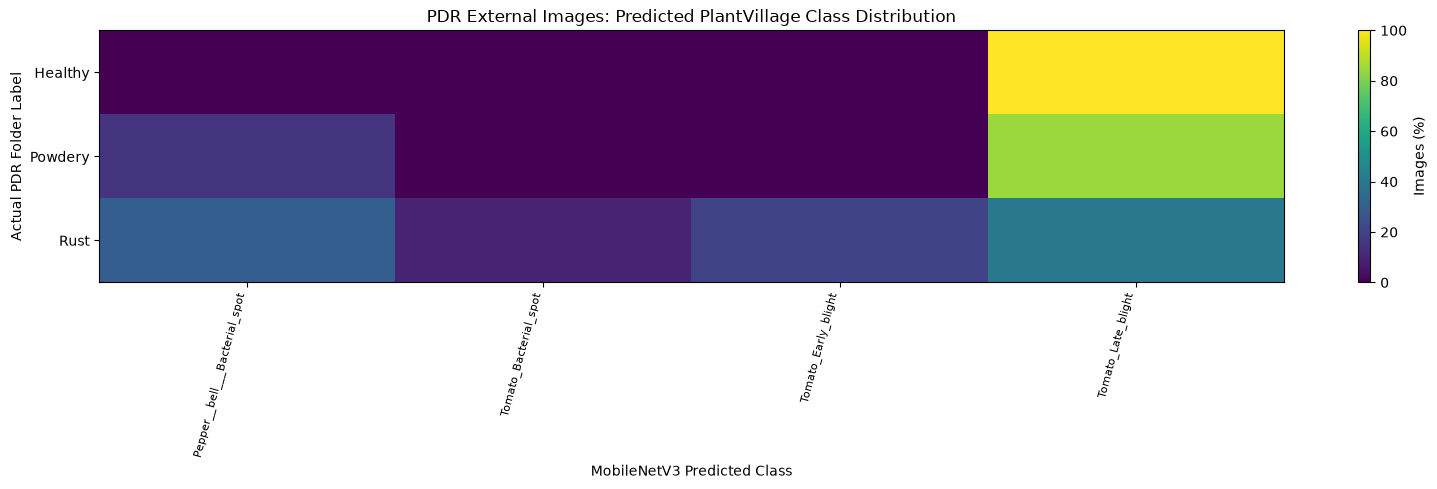

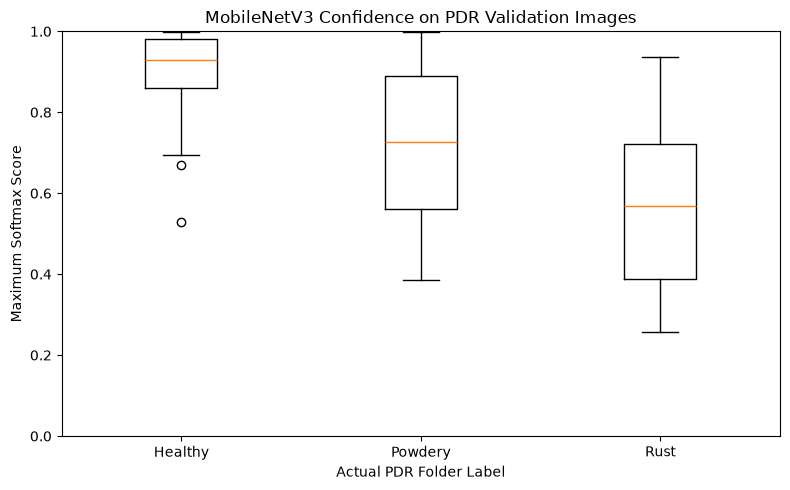

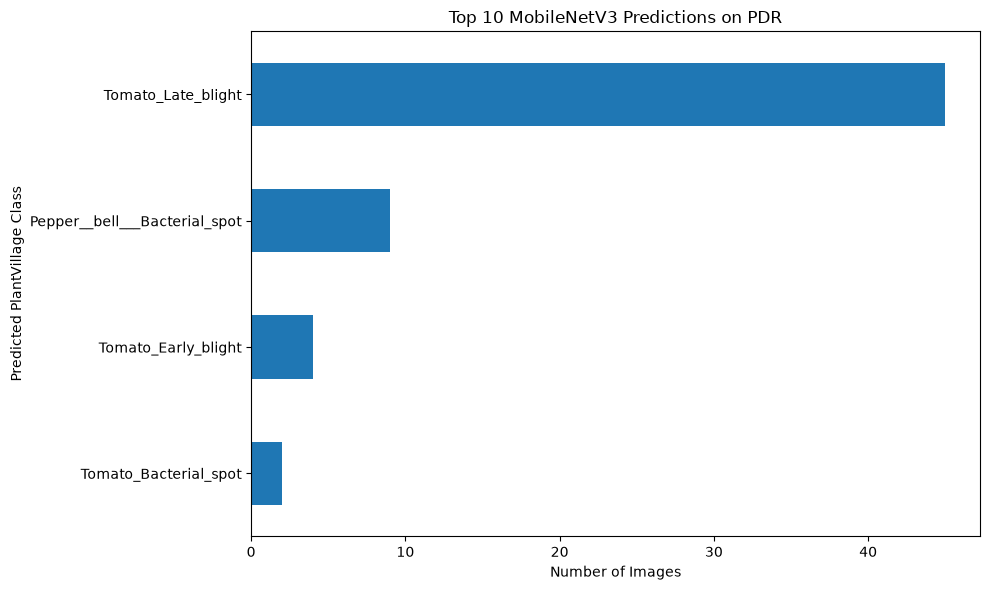

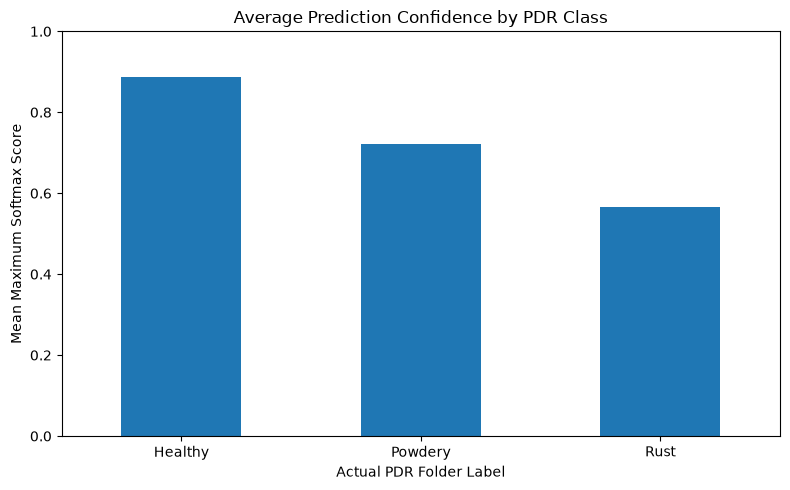

All PDR external analysis figures saved.


In [24]:

# -----------------------------------------
# 1. True PDR class vs predicted model class
# -----------------------------------------
cross_table = pd.crosstab(
    pdr_results["actual_pdr_class"],
    pdr_results["predicted_pv_class"]
)

# Normalize each actual class row into percentages
row_percent = cross_table.div(
    cross_table.sum(axis=1), axis=0
) * 100

fig, ax = plt.subplots(figsize=(16, 5))

im = ax.imshow(
    row_percent.values,
    aspect="auto",
    interpolation="nearest"
)

ax.set_title(
    "PDR External Images: Predicted PlantVillage Class Distribution"
)
ax.set_xlabel("MobileNetV3 Predicted Class")
ax.set_ylabel("Actual PDR Folder Label")

ax.set_xticks(range(len(row_percent.columns)))
ax.set_xticklabels(
    row_percent.columns,
    rotation=75,
    ha="right",
    fontsize=8
)

ax.set_yticks(range(len(row_percent.index)))
ax.set_yticklabels(row_percent.index)

plt.colorbar(im, ax=ax, label="Images (%)")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "pdr_prediction_distribution_heatmap.png",
    dpi=300
)
plt.show()


# -----------------------------------------
# 2. Prediction confidence by PDR class
# -----------------------------------------
groups = [
    pdr_results.loc[
        pdr_results["actual_pdr_class"] == label,
        "confidence"
    ].values
    for label in pdr_dataset.classes
]

plt.figure(figsize=(8, 5))
plt.boxplot(groups, tick_labels=pdr_dataset.classes)

plt.title("MobileNetV3 Confidence on PDR Validation Images")
plt.xlabel("Actual PDR Folder Label")
plt.ylabel("Maximum Softmax Score")
plt.ylim(0, 1)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "pdr_confidence_by_class.png",
    dpi=300
)
plt.show()


# -----------------------------------------
# 3. Most frequent predicted classes
# -----------------------------------------
prediction_counts = (
    pdr_results["predicted_pv_class"]
    .value_counts()
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))
prediction_counts.plot(kind="barh")

plt.title("Top 10 MobileNetV3 Predictions on PDR")
plt.xlabel("Number of Images")
plt.ylabel("Predicted PlantVillage Class")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "pdr_top_predicted_classes.png",
    dpi=300
)
plt.show()


# -----------------------------------------
# 4. Mean confidence by actual PDR class
# -----------------------------------------
mean_confidence = (
    pdr_results.groupby("actual_pdr_class")["confidence"]
    .mean()
)

plt.figure(figsize=(8, 5))
mean_confidence.plot(kind="bar")

plt.title("Average Prediction Confidence by PDR Class")
plt.xlabel("Actual PDR Folder Label")
plt.ylabel("Mean Maximum Softmax Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "pdr_mean_confidence.png",
    dpi=300
)
plt.show()

print("All PDR external analysis figures saved.")


In [25]:

pdr_summary = (
    pdr_results.groupby("actual_pdr_class")
    .agg(
        image_count=("confidence", "count"),
        mean_confidence=("confidence", "mean"),
        min_confidence=("confidence", "min"),
        max_confidence=("confidence", "max")
    )
    .reset_index()
)

pdr_summary.to_csv(
    REPORT_DIR / "pdr_external_summary.csv",
    index=False
)

display(pdr_summary)

print("Summary saved:", REPORT_DIR / "pdr_external_summary.csv")
print("Figures folder:", FIGURE_DIR)


,actual_pdr_class,image_count,mean_confidence,min_confidence,max_confidence
0,Healthy,20,0.886707,0.529276,0.999121
1,Powdery,20,0.721114,0.386622,0.998810
2,Rust,20,0.565645,0.257803,0.936632


Summary saved: D:\dsc_1\ML\AgriCropDisease_Research_Project\reports\pdr_external_summary.csv
Figures folder: D:\dsc_1\ML\AgriCropDisease_Research_Project\figures


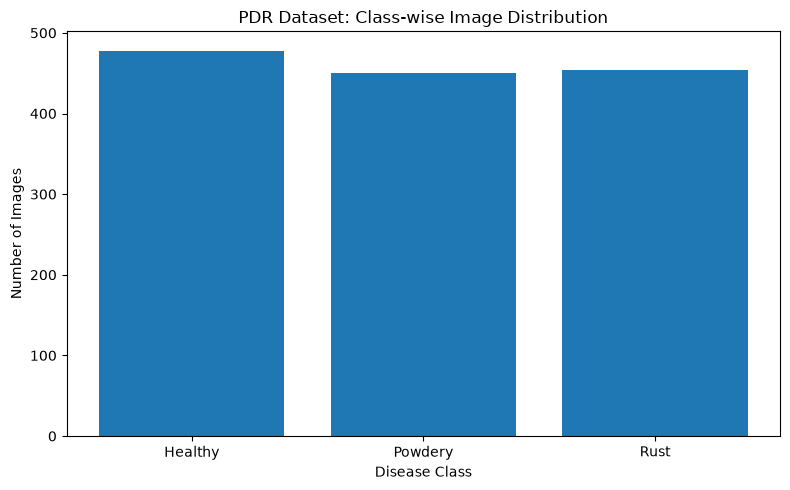

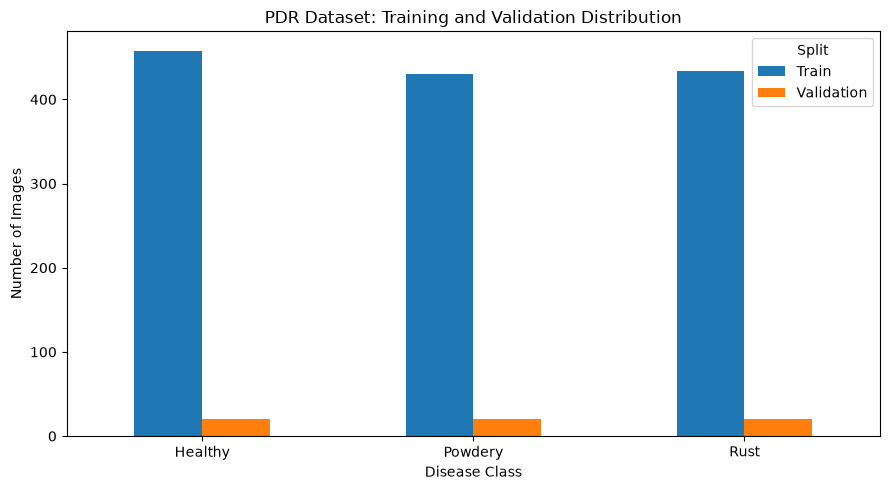

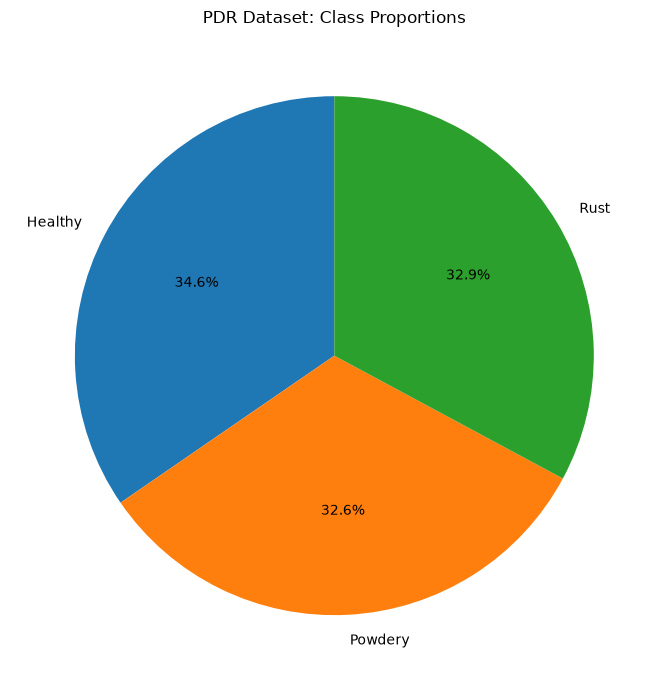

PDR visualization summary:


,Class,Split,Images
0,Healthy,Train,458
1,Powdery,Train,430
2,Rust,Train,434
3,Healthy,Validation,20
4,Powdery,Validation,20
5,Rust,Validation,20



Total images: 1382
Figures saved in: D:\dsc_1\ML\AgriCropDisease_Research_Project\figures


In [26]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Correct PDR dataset structure
PDR_ROOT = DATASETS_ROOT / "Plant Disease Recognition"

splits = {
    "Train": PDR_ROOT / "Train" / "Train",
    "Validation": PDR_ROOT / "Validation" / "Validation"
}

records = []

for split, folder in splits.items():
    for class_name in ["Healthy", "Powdery", "Rust"]:
        class_folder = folder / class_name

        count = sum(
            1 for f in class_folder.rglob("*")
            if f.is_file() and f.suffix.lower()
            in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
        )

        records.append({
            "Class": class_name,
            "Split": split,
            "Images": count
        })

pdr_summary = pd.DataFrame(records)

# Output directory
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# 1. Class-wise total distribution
class_totals = (
    pdr_summary.groupby("Class")["Images"].sum()
)

plt.figure(figsize=(8, 5))
plt.bar(class_totals.index, class_totals.values)
plt.title("PDR Dataset: Class-wise Image Distribution")
plt.xlabel("Disease Class")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "PDR_class_distribution.png", dpi=300)
plt.show()

# 2. Train versus validation
pivot = pdr_summary.pivot(
    index="Class",
    columns="Split",
    values="Images"
)

pivot.plot(kind="bar", figsize=(9, 5))
plt.title("PDR Dataset: Training and Validation Distribution")
plt.xlabel("Disease Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "PDR_train_validation_distribution.png",
            dpi=300)
plt.show()

# 3. Overall class proportions
plt.figure(figsize=(7, 7))
plt.pie(
    class_totals.values,
    labels=class_totals.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("PDR Dataset: Class Proportions")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "PDR_class_proportions.png", dpi=300)
plt.show()

print("PDR visualization summary:")
display(pdr_summary)

print("\nTotal images:", pdr_summary["Images"].sum())
print("Figures saved in:", FIGURE_DIR)


In [27]:

from datasets import load_dataset

print("Connecting to online PlantDoc dataset...")

plantdoc = load_dataset(
    "geraldmc/plantdoc-full",
    revision="v0.1.0"
)

print("Connection successful!")

for split_name, split_data in plantdoc.items():
    print(split_name, ":", len(split_data), "images")

print("\nDataset columns:")
print(plantdoc["train"].column_names)


Connecting to online PlantDoc dataset...


Connection successful!
train : 2578 images

Dataset columns:
['image', 'class_label', 'class_idx', 'host', 'disease', 'is_healthy', 'split', 'filename']


In [28]:

import pandas as pd

plantdoc_df = pd.DataFrame({
    "class_label": plantdoc["train"]["class_label"],
    "host": plantdoc["train"]["host"],
    "disease": plantdoc["train"]["disease"],
    "split": plantdoc["train"]["split"]
})

print("PlantDoc class distribution:")

display(
    plantdoc_df.groupby(
        ["class_label", "split"]
    ).size().unstack(fill_value=0)
)

print("\nTotal images:", len(plantdoc_df))
print("Unique classes:", plantdoc_df["class_label"].nunique())






PlantDoc class distribution:


split,test,train
class_label,,
Apple Scab Leaf,10,83
Apple leaf,9,82
Apple rust leaf,10,79
Bell_pepper leaf,8,53
Bell_pepper leaf spot,9,62
Blueberry leaf,11,106
Cherry leaf,10,47
Corn Gray leaf spot,4,64
Corn leaf blight,12,180



Total images: 2578
Unique classes: 28


## 12. Save run information and review output files

The PlantVillage classifier and evidence retrieval are separate components. This is not end-to-end image-text fusion. PDR and Cassava are inspected but are **not** evaluated by the PlantVillage classifier because their label sets are not yet mapped compatibly.

In [29]:
run_info = {
    "project": "Crop disease detection with MobileNetV3, Grad-CAM and local TF-IDF evidence retrieval",
    "seed": SEED,
    "image_size": IMG_SIZE,
    "batch_size": BATCH_SIZE,
    "max_per_class": MAX_PER_CLASS,
    "epochs_head": EPOCHS_HEAD,
    "fine_tuning_enabled": RUN_FINE_TUNING,
    "plantvillage_root": str(PLANT_ROOT),
    "class_names": class_names,
    "train_images": len(train_set),
    "validation_images": len(val_set),
    "test_images": len(test_set),
    "torch_version": torch.__version__,
    "torchvision_version": torchvision.__version__,
    "device": str(device),
    "checkpoint": str(best_path),
    "test_metrics": metrics
}
with open(OUTPUT_DIR / "run_metadata.json", "w", encoding="utf-8") as f:
    json.dump(run_info, f, indent=2)

print("Saved outputs:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print(path.name)
print("\nSaved model:", best_path)
print("Saved knowledge base template:", KB_PATH)

Saved outputs:
classification_report.csv
confusion_matrix.png
figures
reports
run_metadata.json
test_metrics.json
training_history.csv

Saved model: D:\dsc_1\ML\AgriCropDisease_Research_Project\models\mobilenetv3_plantvillage_best.pth
Saved knowledge base template: D:\dsc_1\ML\AgriCropDisease_Research_Project\knowledge_base\knowledge_base.csv


#### comparision of HOG + SVM, HOG + Random Forest, HOG + KNNY, existing MobileNetV3-Small

In [30]:

print("Available dataset variables:")

for name in [
    "train_ds", "val_ds", "test_ds",
    "train_paths", "val_paths", "test_paths",
    "train_df", "val_df", "test_df",
    "class_names", "IMG_SIZE", "device"
]:
    if name in globals():
        obj = globals()[name]
        try:
            print(name, "->", len(obj))
        except TypeError:
            print(name, "->", obj)


Available dataset variables:
train_ds -> 20638
class_names -> 15
IMG_SIZE -> 224
device -> cpu


In [31]:

print("Checking dataset and split variables...\n")

for name, obj in globals().copy().items():
    if any(word in name.lower() for word in [
        "dataset", "split", "indices", "loader",
        "train_idx", "val_idx", "test_idx"
    ]):
        if not name.startswith("_"):
            try:
                print(name, ":", type(obj).__name__, "| Length:", len(obj))
            except (TypeError, AttributeError):
                print(name, ":", type(obj).__name__)


Checking dataset and split variables...

DATASETS_ROOT : WindowsPath
datasets : module
DataLoader : type
train_test_split : function
split : str | Length: 10
split_path : WindowsPath
all_indices : ndarray | Length: 20638
class_indices : ndarray | Length: 1591
selected_indices : ndarray | Length: 2250
train_idx : ndarray | Length: 1575
val_idx : ndarray | Length: 337
test_idx : ndarray | Length: 338
train_loader : DataLoader | Length: 99
val_loader : DataLoader | Length: 22
test_loader : DataLoader | Length: 22
split_summary : DataFrame | Length: 3
split_name : str | Length: 5
pdr_dataset : ImageFolder | Length: 60
pdr_loader : DataLoader | Length: 4
top_indices : Tensor | Length: 12
splits : dict | Length: 2
load_dataset : function
split_data : Dataset | Length: 2578


In [32]:

print("Checking image path and label variables:\n")

for name, obj in globals().copy().items():
    if any(word in name.lower() for word in [
        "path", "file", "label", "target", "class"
    ]):
        if not name.startswith("_"):
            try:
                print(
                    name,
                    "->",
                    type(obj).__name__,
                    "| Length:",
                    len(obj)
                )
            except (TypeError, AttributeError):
                print(name, "->", type(obj).__name__)

print("\nSplit file:", split_path)


Checking image path and label variables:

Path -> type
MAX_PER_CLASS -> int
immediate_class_folders -> function
nested_classes -> list | Length: 15
outer_classes -> list | Length: 16
split_path -> WindowsPath
mapping_path -> WindowsPath
class_names -> list | Length: 15
targets -> ndarray | Length: 20638
class_id -> int
class_indices -> ndarray | Length: 1591
selected_targets -> ndarray | Length: 2250
temp_targets -> ndarray | Length: 675
labels -> Tensor | Length: 12
label -> Tensor
best_path -> WindowsPath
classification_report -> function
sample_path -> WindowsPath
KB_PATH -> WindowsPath
csv_files -> list | Length: 0
class_folder -> WindowsPath
image_files -> list | Length: 60
class_folders -> list | Length: 1
pdr_classes -> list | Length: 2
image_path -> WindowsPath
CHECKPOINT_PATH -> WindowsPath
model_class_names -> list | Length: 15
actual_class -> str | Length: 4
predicted_class -> str | Length: 19
prediction_path -> WindowsPath
class_name -> str | Length: 4
class_totals -> Serie

In [33]:

print("Dataset type:", type(train_ds))
print("\nDataset attributes:")

for attr in ["samples", "imgs", "paths", "targets", "classes", "root"]:
    if hasattr(train_ds, attr):
        value = getattr(train_ds, attr)
        print(f"\n{attr}:")
        print("Type:", type(value))
        try:
            print("Length:", len(value))
            print("First item:", value[0])
        except (TypeError, IndexError, KeyError):
            print(value)


Dataset type: <class 'torchvision.datasets.folder.ImageFolder'>

Dataset attributes:

samples:
Type: <class 'list'>
Length: 20638
First item: ('D:\\dsc_1\\ML\\MyDrive\\CropDiseaseProject\\datasets\\PlantVillage\\PlantVillage\\Pepper__bell___Bacterial_spot\\0022d6b7-d47c-4ee2-ae9a-392a53f48647___JR_B.Spot 8964.JPG', 0)

imgs:
Type: <class 'list'>
Length: 20638
First item: ('D:\\dsc_1\\ML\\MyDrive\\CropDiseaseProject\\datasets\\PlantVillage\\PlantVillage\\Pepper__bell___Bacterial_spot\\0022d6b7-d47c-4ee2-ae9a-392a53f48647___JR_B.Spot 8964.JPG', 0)

targets:
Type: <class 'list'>
Length: 20638
First item: 0

classes:
Type: <class 'list'>
Length: 15
First item: Pepper__bell___Bacterial_spot

root:
Type: <class 'str'>
Length: 73
First item: D


### Step 1 — Prepare the comparison dataset


In [34]:
import numpy as np
import pandas as pd

# Get all paths and labels
all_samples = train_ds.samples

all_paths = np.array([item[0] for item in all_samples])
all_labels = np.array([item[1] for item in all_samples])

# Apply the existing split indices to the full dataset
X_train_paths = all_paths[train_idx]
X_val_paths = all_paths[val_idx]
X_test_paths = all_paths[test_idx]

y_train = all_labels[train_idx]
y_val = all_labels[val_idx]
y_test = all_labels[test_idx]

print("Dataset split prepared")
print("-----------------------")
print("Training:", len(X_train_paths))
print("Validation:", len(X_val_paths))
print("Testing:", len(X_test_paths))

print("\nFirst training image:")
print(X_train_paths[0])
print("Class:", class_names[y_train[0]])



Dataset split prepared
-----------------------
Training: 1575
Validation: 337
Testing: 338

First training image:
D:\dsc_1\ML\MyDrive\CropDiseaseProject\datasets\PlantVillage\PlantVillage\Tomato_healthy\b6690f04-b49a-43eb-8804-67eeffae7950___RS_HL 0518.JPG
Class: Tomato_healthy


### Step 2 — Verify the split


In [35]:
print("Checking split consistency...\n")

print("Selected images:", len(selected_indices))
print("Train + Validation + Test:",
      len(train_idx) + len(val_idx) + len(test_idx))

print("\nChecking index overlap:")
print("Train/Validation:",
      len(set(train_idx) & set(val_idx)))
print("Train/Test:",
      len(set(train_idx) & set(test_idx)))
print("Validation/Test:",
      len(set(val_idx) & set(test_idx)))

print("\nChecking whether split indices belong to selected images:")
print("Train indices all selected:",
      np.isin(train_idx, selected_indices).all())
print("Validation indices all selected:",
      np.isin(val_idx, selected_indices).all())
print("Test indices all selected:",
      np.isin(test_idx, selected_indices).all())


Checking split consistency...

Selected images: 2250
Train + Validation + Test: 2250

Checking index overlap:
Train/Validation: 0
Train/Test: 0
Validation/Test: 0

Checking whether split indices belong to selected images:
Train indices all selected: True
Validation indices all selected: True
Test indices all selected: True


### Step 3 — Extract HOG and colour features
We'll combine:
- HOG: captures leaf edges, shapes and texture patterns.
- Colour histograms: capture colour differences associated with disease symptoms.

In [36]:

import cv2
import numpy as np
from tqdm.auto import tqdm

from skimage.feature import hog

# HOG configuration
HOG_SIZE = 128
HOG_CELL = (8, 8)
HOG_BLOCK = (2, 2)

def extract_features(image_paths):
    features = []

    for image_path in tqdm(image_paths):
        # Read and resize image
        image = cv2.imread(str(image_path))

        if image is None:
            raise ValueError(f"Could not read image: {image_path}")

        image = cv2.resize(image, (HOG_SIZE, HOG_SIZE))

        # HOG features from grayscale image
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

        hog_features = hog(
            gray,
            orientations=9,
            pixels_per_cell=HOG_CELL,
            cells_per_block=HOG_BLOCK,
            block_norm="L2-Hys"
        )

        # Colour histogram in HSV
        hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

        hist = cv2.calcHist(
            [hsv], [0, 1, 2], None,
            [8, 8, 8], [0, 180, 0, 256, 0, 256]
        )

        colour_features = cv2.normalize(
            hist, None
        ).flatten()

        # Combine HOG and colour features
        combined = np.concatenate([
            hog_features,
            colour_features
        ])

        features.append(combined)

    return np.array(features, dtype=np.float32)


print("Extracting training features...")
X_train_features = extract_features(X_train_paths)

print("\nExtracting validation features...")
X_val_features = extract_features(X_val_paths)

print("\nExtracting testing features...")
X_test_features = extract_features(X_test_paths)

print("\nFEATURE EXTRACTION COMPLETED")
print("Training feature shape:", X_train_features.shape)
print("Validation feature shape:", X_val_features.shape)
print("Testing feature shape:", X_test_features.shape)


Extracting training features...


  0%|          | 0/1575 [00:00<?, ?it/s]


Extracting validation features...


  0%|          | 0/337 [00:00<?, ?it/s]


Extracting testing features...


  0%|          | 0/338 [00:00<?, ?it/s]


FEATURE EXTRACTION COMPLETED
Training feature shape: (1575, 8612)
Validation feature shape: (337, 8612)
Testing feature shape: (338, 8612)


### Step 4 — Train SVM, Random Forest and KNN

In [ ]:

import time
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score

# ============================================
# DEFINE OPTIMIZED TRADITIONAL ML MODELS
# ============================================

traditional_models = {

    # Faster Linear SVM
    "SVM": make_pipeline(
        StandardScaler(),
        SVC(
            kernel="linear",
            C=1,
            cache_size=1000
        )
    ),

    # Random Forest
    "Random Forest": RandomForestClassifier(
        n_estimators=150,
        max_depth=None,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced"
    ),

    # KNN
    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(
            n_neighbors=5,
            weights="distance",
            n_jobs=-1
        )
    )
}

comparison_results = []
trained_models = {}

# ============================================
# TRAIN AND EVALUATE MODELS
# ============================================

for model_name, model in traditional_models.items():

    print(f"\nTraining {model_name}...", flush=True)

    start_time = time.time()

    model.fit(X_train_features, y_train)

    training_time = time.time() - start_time

    # Validation predictions
    val_predictions = model.predict(X_val_features)

    val_accuracy = accuracy_score(
        y_val, val_predictions
    )

    val_f1 = f1_score(
        y_val,
        val_predictions,
        average="macro",
        zero_division=0
    )

    trained_models[model_name] = model

    comparison_results.append({
        "Model": model_name,
        "Training Time (seconds)": round(training_time, 2),
        "Validation Accuracy": round(val_accuracy, 4),
        "Validation Macro F1": round(val_f1, 4)
    })

    print("Training time:", round(training_time, 2), "seconds")
    print("Validation accuracy:", round(val_accuracy, 4))
    print("Validation macro F1:", round(val_f1, 4))

# ============================================
# DISPLAY RESULTS
# ============================================

print("\nTRADITIONAL ML TRAINING SUMMARY")

traditional_results_df = pd.DataFrame(comparison_results)

display(traditional_results_df)

print("\nAll traditional ML models trained successfully!")


In [38]:

import time
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

test_results = []
test_predictions = {}

for model_name, model in trained_models.items():

    print(f"\nEvaluating {model_name}...")

    start_time = time.time()
    predictions = model.predict(X_test_features)
    prediction_time = time.time() - start_time

    test_predictions[model_name] = predictions

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(
        y_test, predictions,
        average="macro",
        zero_division=0
    )
    recall = recall_score(
        y_test, predictions,
        average="macro",
        zero_division=0
    )
    macro_f1 = f1_score(
        y_test, predictions,
        average="macro",
        zero_division=0
    )

    test_results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "Macro F1": macro_f1,
        "Prediction Time (seconds)": prediction_time,
        "Prediction Time (ms/image)": (
            prediction_time / len(y_test) * 1000
        )
    })

    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("Macro F1:", round(macro_f1, 4))
    print("Prediction time:", round(prediction_time, 4), "seconds")

# Create final traditional ML test-results table
traditional_test_results = pd.DataFrame(test_results)

print("\nTRADITIONAL ML — FINAL TEST RESULTS")
display(
    traditional_test_results.round(4)
)

# Save the results
results_folder = r"D:\dsc_1\ML\AgriCropDisease_Research_Project\reports"

import os
os.makedirs(results_folder, exist_ok=True)

traditional_test_results.to_csv(
    os.path.join(results_folder, "traditional_ml_test_results.csv"),
    index=False
)

print("\nResults saved successfully.")



Evaluating SVM...
Accuracy: 0.6598
Precision: 0.6699
Recall: 0.6593
Macro F1: 0.6553
Prediction time: 50.4635 seconds

Evaluating Random Forest...
Accuracy: 0.8343
Precision: 0.848
Recall: 0.8353
Macro F1: 0.8282
Prediction time: 0.3151 seconds

Evaluating KNN...
Accuracy: 0.3018
Precision: 0.5752
Recall: 0.3007
Macro F1: 0.2811
Prediction time: 0.714 seconds

TRADITIONAL ML — FINAL TEST RESULTS


,Model,Accuracy,Precision,Recall,Macro F1,Prediction Time (seconds),Prediction Time (ms/image)
0,SVM,0.6598,0.6699,0.6593,0.6553,50.4635,149.3002
1,Random Forest,0.8343,0.8480,0.8353,0.8282,0.3151,0.9323
2,KNN,0.3018,0.5752,0.3007,0.2811,0.7140,2.1123



Results saved successfully.


In [39]:

from pathlib import Path

project_root = Path(
    r"D:\dsc_1\ML\AgriCropDisease_Research_Project"
)

print("Searching for saved MobileNetV3 metrics...\n")

metric_files = list(project_root.rglob("test_metrics.json"))

if metric_files:
    for file in metric_files:
        print("Found:", file)
else:
    print("test_metrics.json was not found.")

print("\nChecking saved model files:")
for file in (project_root / "models").glob("*"):
    print(file.name)

print("\nChecking report files:")
for file in project_root.rglob("classification_report.csv"):
    print(file)


Searching for saved MobileNetV3 metrics...

Found: D:\dsc_1\ML\AgriCropDisease_Research_Project\outputs\test_metrics.json

Checking saved model files:
.gitkeep
mobilenetv3_plantvillage_best.pth

Checking report files:
D:\dsc_1\ML\AgriCropDisease_Research_Project\outputs\classification_report.csv


In [40]:

import json

metrics_path = (
    r"D:\dsc_1\ML\AgriCropDisease_Research_Project\outputs\test_metrics.json"
)

with open(metrics_path, "r") as file:
    mobilenet_saved_metrics = json.load(file)

print("MOBILENETV3 TEST RESULTS")
print("------------------------")
print(json.dumps(mobilenet_saved_metrics, indent=4))



MOBILENETV3 TEST RESULTS
------------------------
{
    "test_accuracy": 0.8668639053254438,
    "macro_precision": 0.8844903698424661,
    "macro_recall": 0.866403162055336,
    "macro_f1": 0.8664771219048696,
    "test_images": 338,
    "classes": [
        "Pepper__bell___Bacterial_spot",
        "Pepper__bell___healthy",
        "Potato___Early_blight",
        "Potato___Late_blight",
        "Potato___healthy",
        "Tomato_Bacterial_spot",
        "Tomato_Early_blight",
        "Tomato_Late_blight",
        "Tomato_Leaf_Mold",
        "Tomato_Septoria_leaf_spot",
        "Tomato_Spider_mites_Two_spotted_spider_mite",
        "Tomato__Target_Spot",
        "Tomato__Tomato_YellowLeaf__Curl_Virus",
        "Tomato__Tomato_mosaic_virus",
        "Tomato_healthy"
    ]
}


In [41]:

import pandas as pd
from pathlib import Path

# MobileNetV3 metrics from the saved experiment
mobilenet_row = {
    "Model": "MobileNetV3-Small",
    "Accuracy": mobilenet_saved_metrics["test_accuracy"],
    "Precision": mobilenet_saved_metrics["macro_precision"],
    "Recall": mobilenet_saved_metrics["macro_recall"],
    "Macro F1": mobilenet_saved_metrics["macro_f1"],
    "Prediction Time (seconds)": None,
    "Prediction Time (ms/image)": None
}

# Add MobileNetV3 to the traditional ML results
mobilenet_df = pd.DataFrame([mobilenet_row])

combined_results = pd.concat(
    [traditional_test_results, mobilenet_df],
    ignore_index=True
)

# Convert metrics to percentages for presentation
display_results = combined_results.copy()

for col in ["Accuracy", "Precision", "Recall", "Macro F1"]:
    display_results[col] = (
        display_results[col] * 100
    ).round(2)

print("FINAL FOUR-MODEL COMPARISON")
display(display_results)

# Save research results
report_dir = Path(
    r"D:\dsc_1\ML\AgriCropDisease_Research_Project\reports"
)

report_dir.mkdir(parents=True, exist_ok=True)

combined_results.to_csv(
    report_dir / "four_model_comparison.csv",
    index=False
)

display_results.to_csv(
    report_dir / "four_model_comparison_percentage.csv",
    index=False
)

print("\nBoth comparison files saved successfully:")
print(report_dir / "four_model_comparison.csv")
print(report_dir / "four_model_comparison_percentage.csv")


FINAL FOUR-MODEL COMPARISON


,Model,Accuracy,Precision,Recall,Macro F1,Prediction Time (seconds),Prediction Time (ms/image)
0,SVM,65.98,66.99,65.93,65.53,50.463466,149.300194
1,Random Forest,83.43,84.80,83.53,82.82,0.315133,0.932346
2,KNN,30.18,57.52,30.07,28.11,0.71396,2.112309
3,MobileNetV3-Small,86.69,88.45,86.64,86.65,None,None



Both comparison files saved successfully:
D:\dsc_1\ML\AgriCropDisease_Research_Project\reports\four_model_comparison.csv
D:\dsc_1\ML\AgriCropDisease_Research_Project\reports\four_model_comparison_percentage.csv


In [42]:

import numpy as np

mobile_test_dataset = test_loader.dataset

print("MobileNetV3 test dataset type:",
      type(mobile_test_dataset).__name__)

if hasattr(mobile_test_dataset, "indices"):

    mobile_test_indices = np.asarray(
        mobile_test_dataset.indices
    )

    print("MobileNetV3 test images:", len(mobile_test_indices))
    print("Traditional ML test images:", len(test_idx))

    print(
        "Exact same order:",
        np.array_equal(mobile_test_indices, test_idx)
    )

    print(
        "Same images, possibly different order:",
        np.array_equal(
            np.sort(mobile_test_indices),
            np.sort(test_idx)
        )
    )

else:
    print("The test loader does not expose Subset indices.")
    print("Underlying dataset:", type(mobile_test_dataset).__name__)


MobileNetV3 test dataset type: Subset
MobileNetV3 test images: 338
Traditional ML test images: 338
Exact same order: True
Same images, possibly different order: True


In [43]:

import torch

print("Existing PyTorch model variables:\n")

for name, obj in globals().copy().items():
    if isinstance(obj, torch.nn.Module):
        print(name, "->", type(obj).__name__)

print("\nCheckpoint path:")
print(best_path)

print("\nInspecting checkpoint contents:")

checkpoint = torch.load(
    best_path,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint type:", type(checkpoint).__name__)

if isinstance(checkpoint, dict):
    print("Checkpoint keys:", list(checkpoint.keys()))

    for key, value in checkpoint.items():
        if isinstance(value, dict):
            print(f"\n{key}:")
            print("Number of entries:", len(value))
            print("Sample parameter names:", list(value.keys())[:5])
        elif isinstance(value, torch.Tensor):
            print(key, "-> Tensor:", tuple(value.shape))
        else:
            print(key, "->", type(value).__name__)


Existing PyTorch model variables:

criterion -> CrossEntropyLoss
softmax -> Softmax

Checkpoint path:
D:\dsc_1\ML\AgriCropDisease_Research_Project\models\mobilenetv3_plantvillage_best.pth

Inspecting checkpoint contents:
Checkpoint type: dict
Checkpoint keys: ['model_state', 'class_names', 'img_size', 'plant_root', 'seed']

model_state:
Number of entries: 244
Sample parameter names: ['features.0.0.weight', 'features.0.1.weight', 'features.0.1.bias', 'features.0.1.running_mean', 'features.0.1.running_var']
class_names -> list
img_size -> int
plant_root -> str
seed -> int


In [44]:

import torch
import torch.nn as nn
from torchvision import models
import numpy as np
from sklearn.metrics import accuracy_score

# Reconstruct MobileNetV3-Small architecture
mobilenet_model = models.mobilenet_v3_small(weights=None)

# Set output layer for 15 disease classes
in_features = mobilenet_model.classifier[-1].in_features

mobilenet_model.classifier[-1] = nn.Linear(
    in_features,
    len(class_names)
)

# Load previously trained weights
mobilenet_model.load_state_dict(
    checkpoint["model_state"]
)

mobilenet_model = mobilenet_model.to(device)
mobilenet_model.eval()

print("MobileNetV3 checkpoint restored successfully!")

# Generate predictions on the existing test loader
mobilenet_predictions = []
mobilenet_true_labels = []

with torch.inference_mode():

    for images, labels_batch in test_loader:

        images = images.to(device)

        outputs = mobilenet_model(images)

        predictions = torch.argmax(
            outputs, dim=1
        )

        mobilenet_predictions.extend(
            predictions.cpu().numpy()
        )

        mobilenet_true_labels.extend(
            labels_batch.numpy()
        )

mobilenet_predictions = np.array(mobilenet_predictions)
mobilenet_true_labels = np.array(mobilenet_true_labels)

# Verify against traditional ML test labels
print("\nMobileNetV3 test images:",
      len(mobilenet_predictions))

print("True labels match traditional ML:",
      np.array_equal(mobilenet_true_labels, y_test))

print("Newly calculated MobileNetV3 accuracy:",
      round(
          accuracy_score(
              mobilenet_true_labels,
              mobilenet_predictions
          ), 4
      ))

print("Previously saved accuracy:",
      round(mobilenet_saved_metrics["test_accuracy"], 4))


MobileNetV3 checkpoint restored successfully!

MobileNetV3 test images: 338
True labels match traditional ML: True
Newly calculated MobileNetV3 accuracy: 0.8669
Previously saved accuracy: 0.8669


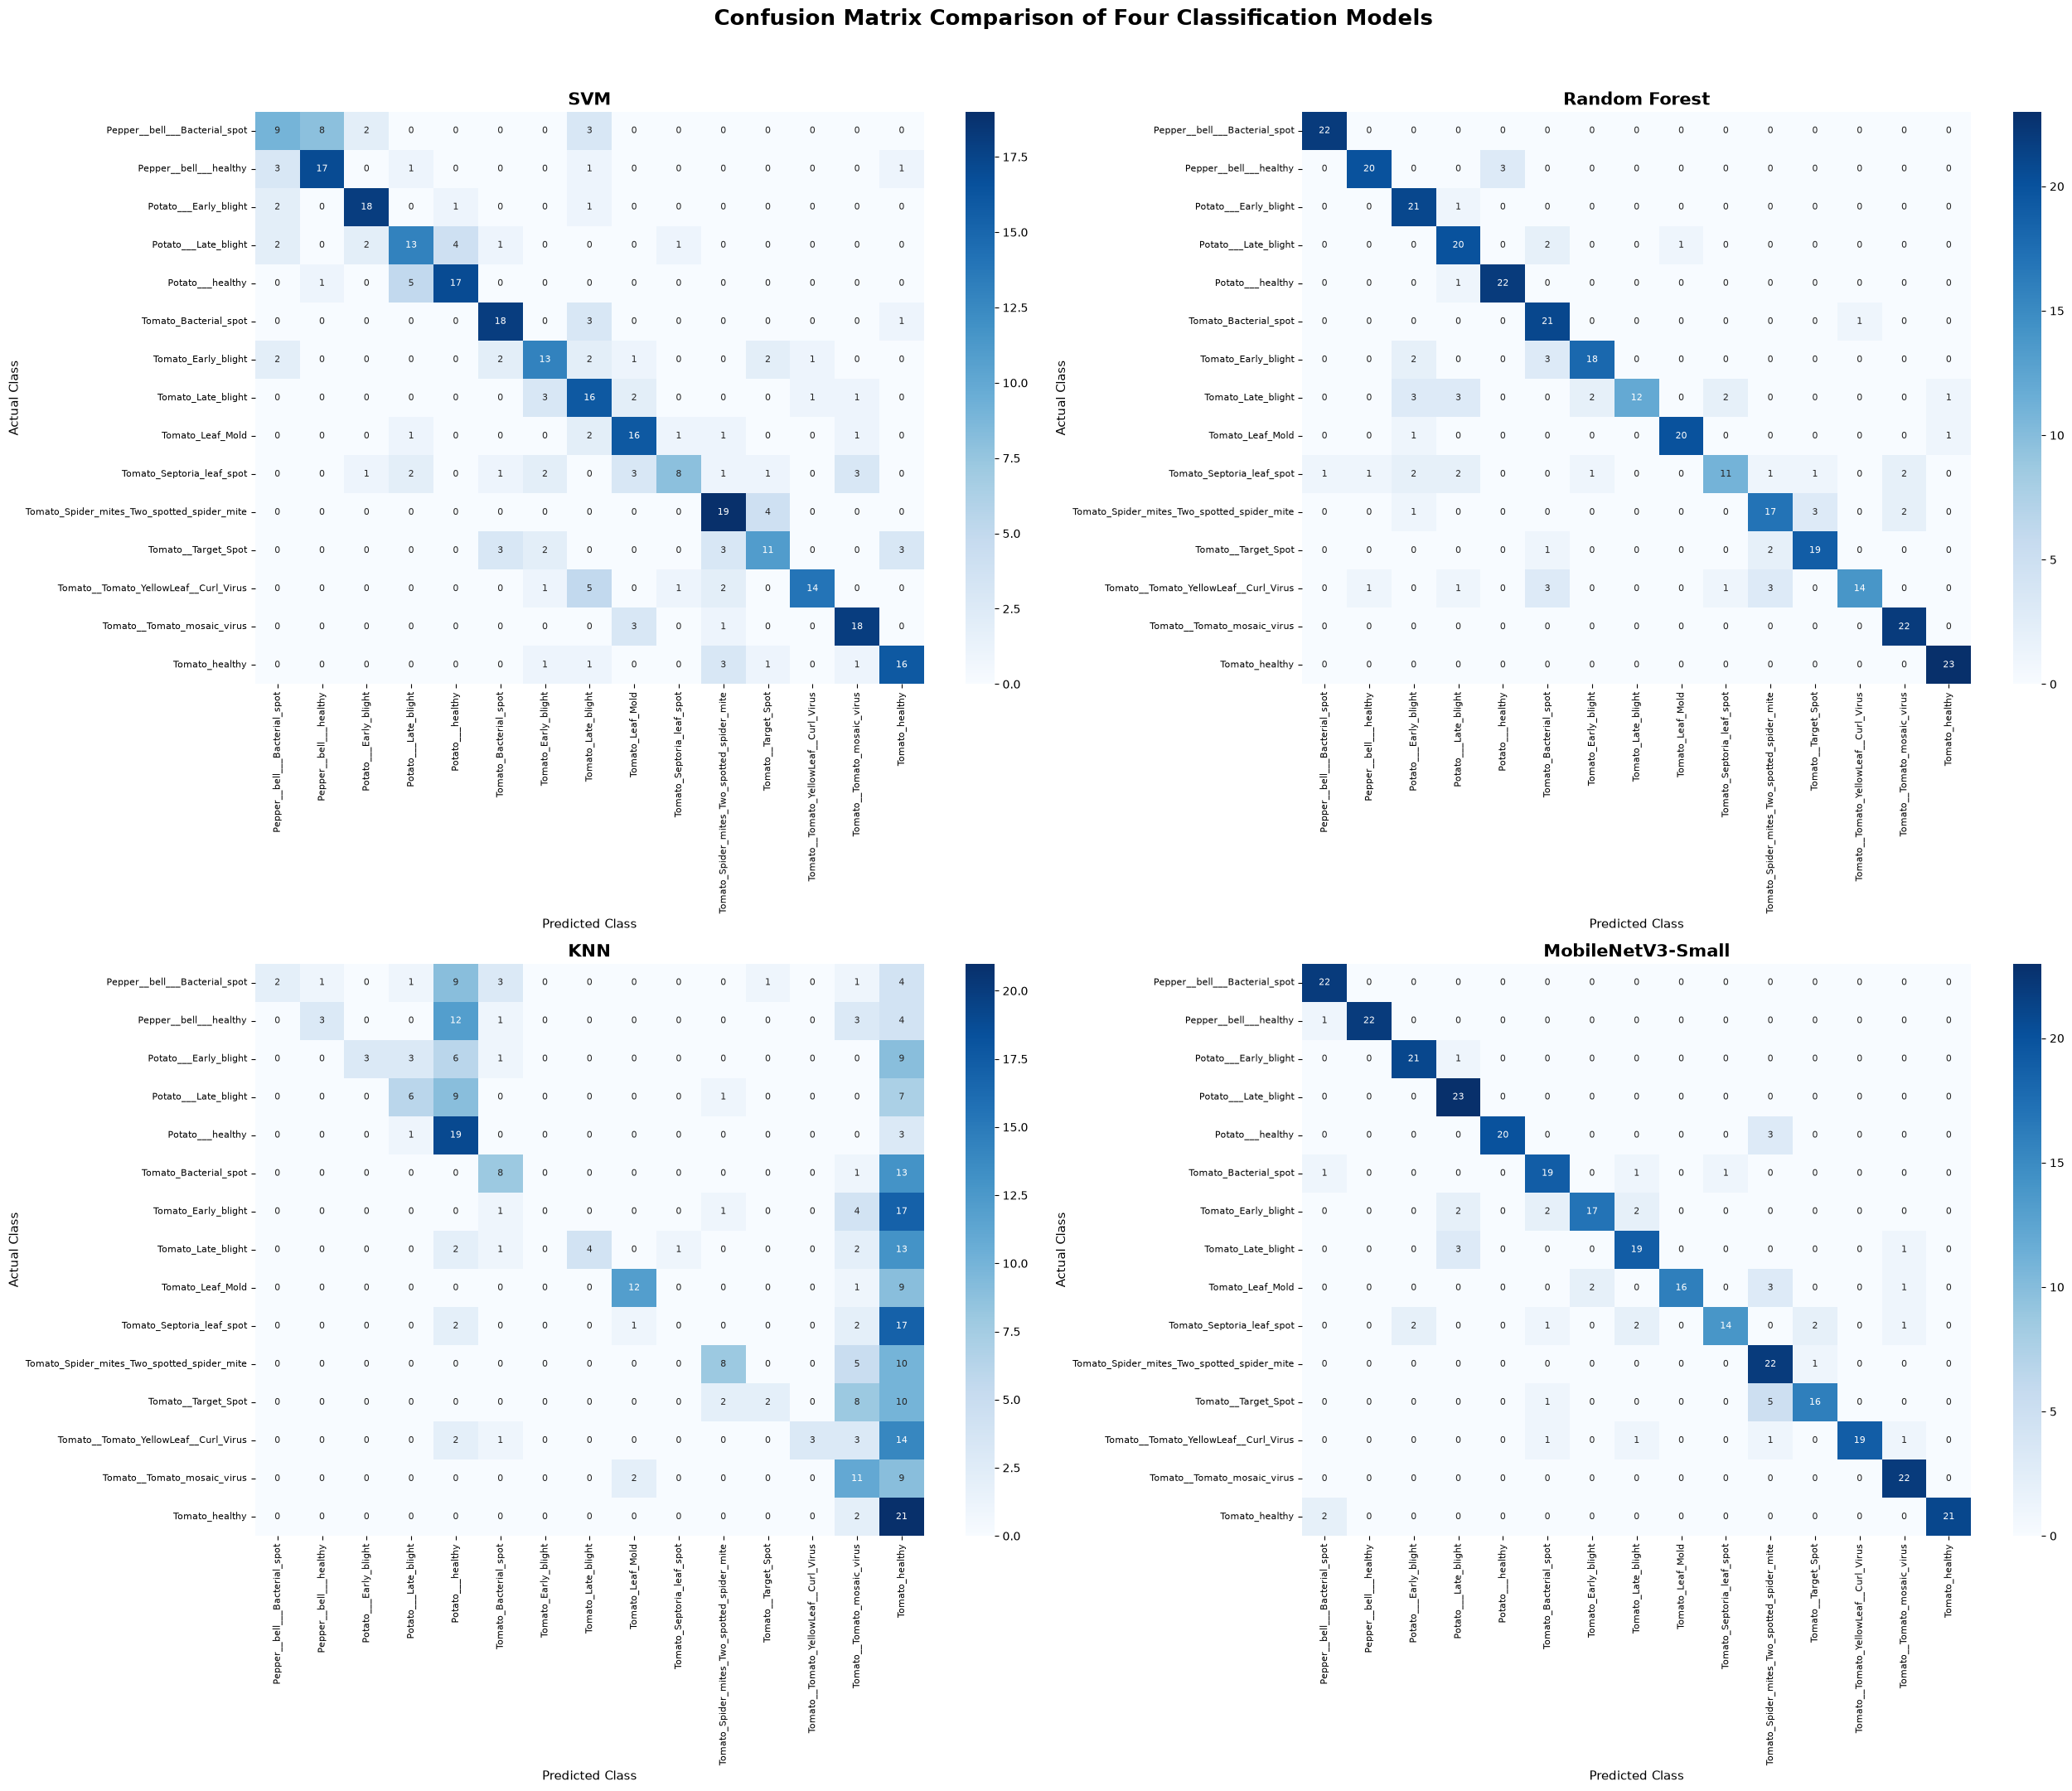

Saved: D:\dsc_1\ML\AgriCropDisease_Research_Project\reports\svm_class_report.csv
Saved: D:\dsc_1\ML\AgriCropDisease_Research_Project\reports\random_forest_class_report.csv
Saved: D:\dsc_1\ML\AgriCropDisease_Research_Project\reports\knn_class_report.csv
Saved: D:\dsc_1\ML\AgriCropDisease_Research_Project\reports\mobilenetv3_small_class_report.csv

CONFUSION MATRICES SAVED
D:\dsc_1\ML\AgriCropDisease_Research_Project\figures\four_model_confusion_matrices.png


In [45]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

from sklearn.metrics import (
    confusion_matrix,
    classification_report
)
from pathlib import Path

# Output folder
figure_dir = Path(
    r"D:\dsc_1\ML\AgriCropDisease_Research_Project\figures"
)

report_dir = Path(
    r"D:\dsc_1\ML\AgriCropDisease_Research_Project\reports"
)

figure_dir.mkdir(parents=True, exist_ok=True)
report_dir.mkdir(parents=True, exist_ok=True)

# Collect predictions from all four models
all_model_predictions = {
    "SVM": test_predictions["SVM"],
    "Random Forest": test_predictions["Random Forest"],
    "KNN": test_predictions["KNN"],
    "MobileNetV3-Small": mobilenet_predictions
}

class_ids = np.arange(len(class_names))

# Create 2x2 confusion matrix figure
fig, axes = plt.subplots(2, 2, figsize=(26, 22))

for ax, (model_name, predictions) in zip(
    axes.flatten(),
    all_model_predictions.items()
):

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=class_ids
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax,
        annot_kws={"size": 8}
    )

    ax.set_title(
        model_name,
        fontsize=15,
        fontweight="bold"
    )

    ax.set_xlabel("Predicted Class", fontsize=11)
    ax.set_ylabel("Actual Class", fontsize=11)

    ax.tick_params(axis="x", labelrotation=90, labelsize=8)
    ax.tick_params(axis="y", labelrotation=0, labelsize=8)

plt.suptitle(
    "Confusion Matrix Comparison of Four Classification Models",
    fontsize=19,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

confusion_path = figure_dir / "four_model_confusion_matrices.png"

plt.savefig(
    confusion_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Generate class-wise classification reports
for model_name, predictions in all_model_predictions.items():

    report = classification_report(
        y_test,
        predictions,
        labels=class_ids,
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(report).transpose()

    safe_name = (
        model_name.lower()
        .replace("-", "_")
        .replace(" ", "_")
    )

    report_path = report_dir / f"{safe_name}_class_report.csv"

    report_df.to_csv(report_path)

    print("Saved:", report_path)

print("\nCONFUSION MATRICES SAVED")
print(confusion_path)


### Create the main performance dashboard


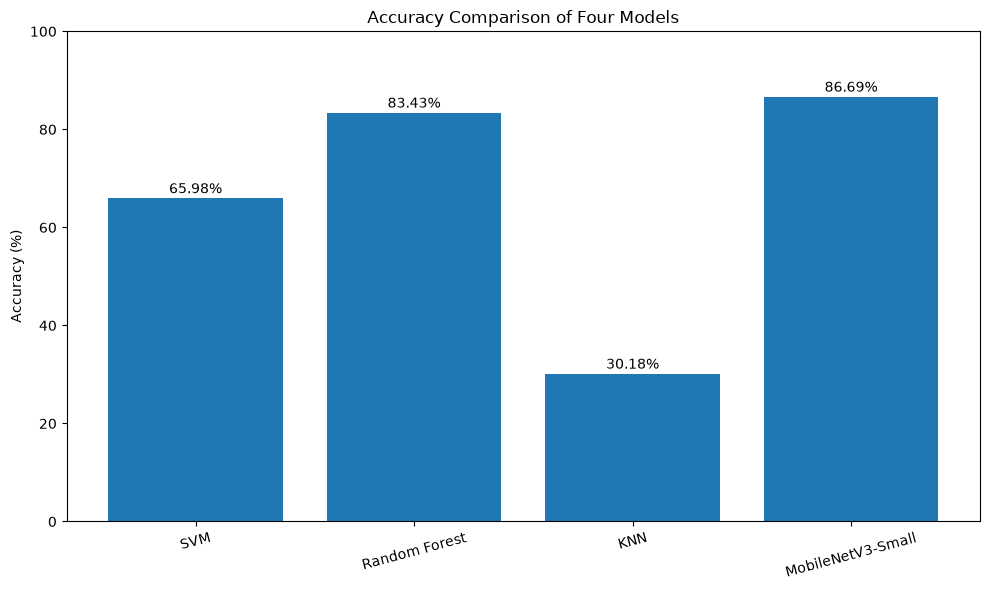

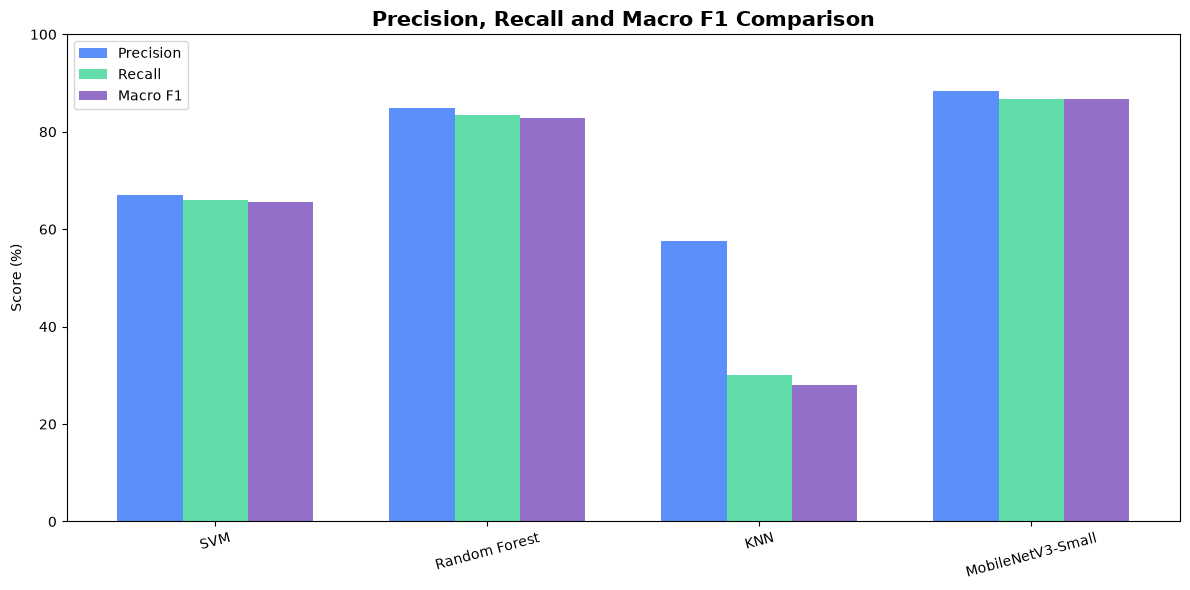

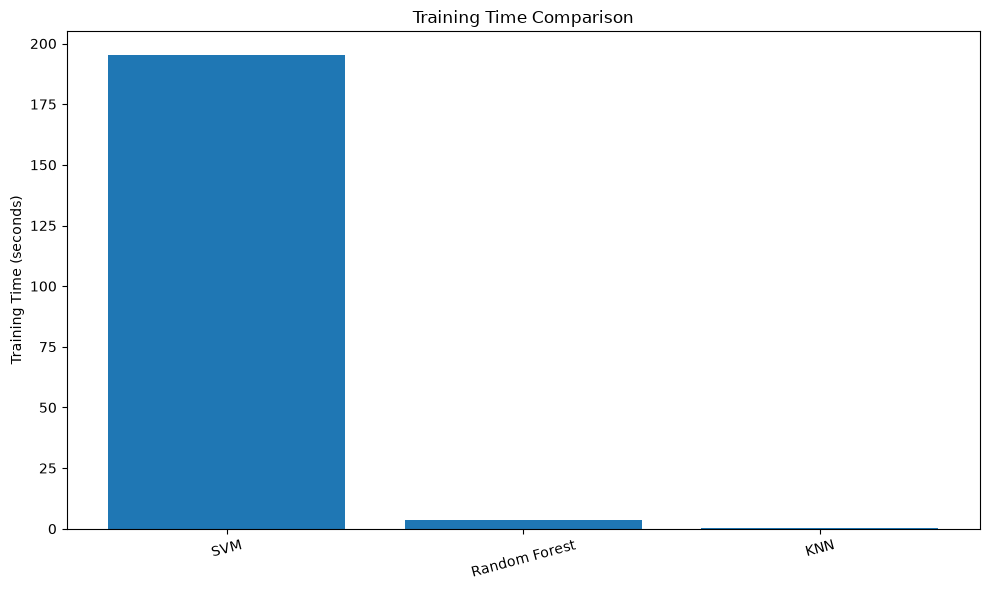

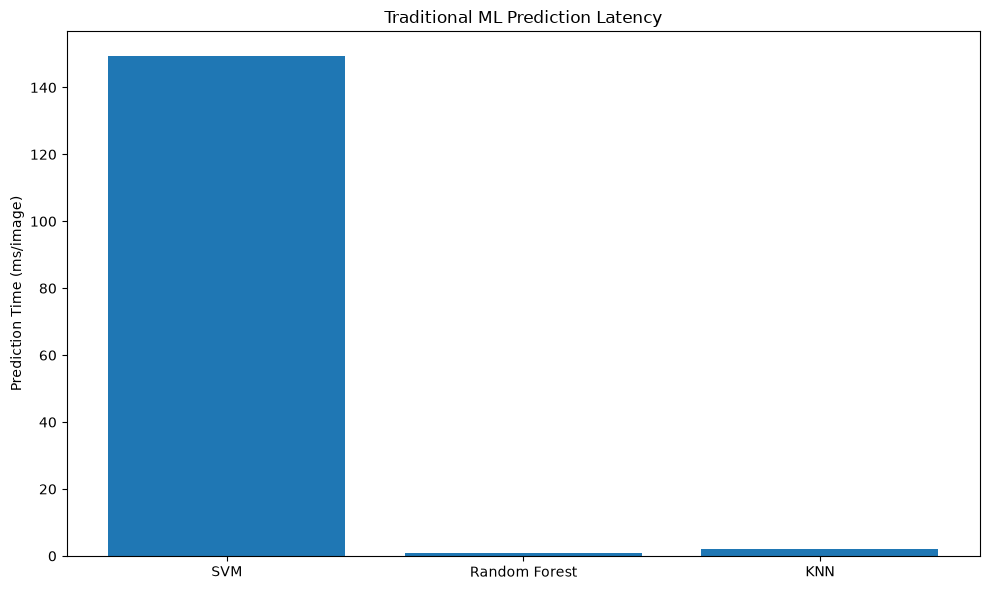

FOUR MAIN VISUALIZATIONS SAVED SUCCESSFULLY!
Location: D:\dsc_1\ML\AgriCropDisease_Research_Project\figures


In [46]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

# Use the combined results already created
df = combined_results.copy()

# Convert metrics to percentages
metrics = ["Accuracy", "Precision", "Recall", "Macro F1"]

for col in metrics:
    df[col] = df[col] * 100

# Output folder
figure_dir = Path(
    r"D:\dsc_1\ML\AgriCropDisease_Research_Project\figures"
)
figure_dir.mkdir(parents=True, exist_ok=True)

# 1. Accuracy comparison
plt.figure(figsize=(10, 6))

bars = plt.bar(df["Model"], df["Accuracy"])

plt.title("Accuracy Comparison of Four Models")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=15)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 1,
        f"{bar.get_height():.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.savefig(figure_dir / "accuracy_comparison.png", dpi=300)
plt.show()



# 2. Precision, Recall and Macro F1 - Custom Colours

x = np.arange(len(df))
width = 0.24

plt.figure(figsize=(12, 6))

plt.bar(
    x - width,
    df["Precision"],
    width,
    label="Precision",
    color="#5B8FF9"
)

plt.bar(
    x,
    df["Recall"],
    width,
    label="Recall",
    color="#61DDAA"
)

plt.bar(
    x + width,
    df["Macro F1"],
    width,
    label="Macro F1",
    color="#9270CA"
)

plt.xticks(x, df["Model"], rotation=15)
plt.ylabel("Score (%)")
plt.ylim(0, 100)

plt.title(
    "Precision, Recall and Macro F1 Comparison",
    fontsize=15,
    fontweight="bold"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    figure_dir / "precision_recall_f1_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 3. Training time comparison
training_times = [195.27, 3.66, 0.46, np.nan]

plt.figure(figsize=(10, 6))

plt.bar(df["Model"], training_times)

plt.ylabel("Training Time (seconds)")
plt.title("Training Time Comparison")
plt.xticks(rotation=15)

plt.tight_layout()
plt.savefig(figure_dir / "training_time_comparison.png", dpi=300)
plt.show()


# 4. Traditional model prediction latency
latency_df = df[
    df["Model"].isin(["SVM", "Random Forest", "KNN"])
]

plt.figure(figsize=(10, 6))

plt.bar(
    latency_df["Model"],
    latency_df["Prediction Time (ms/image)"]
)

plt.ylabel("Prediction Time (ms/image)")
plt.title("Traditional ML Prediction Latency")
plt.tight_layout()

plt.savefig(
    figure_dir / "traditional_prediction_latency.png",
    dpi=300
)
plt.show()

print("FOUR MAIN VISUALIZATIONS SAVED SUCCESSFULLY!")
print("Location:", figure_dir)


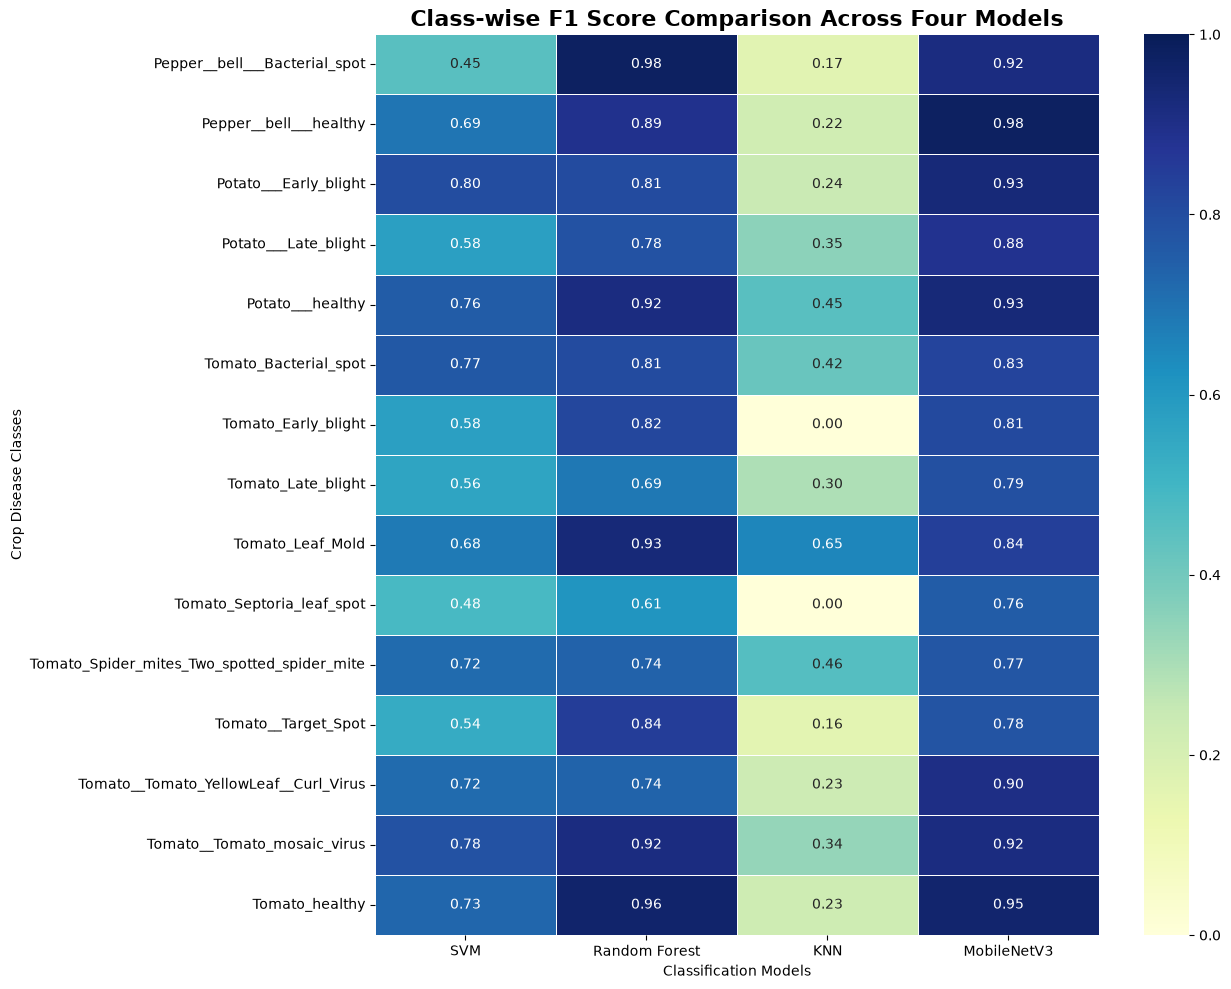

Class-wise F1 heatmap saved successfully!


In [47]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

report_dir = Path(
    r"D:\dsc_1\ML\AgriCropDisease_Research_Project\reports"
)

figure_dir = Path(
    r"D:\dsc_1\ML\AgriCropDisease_Research_Project\figures"
)

model_files = {
    "SVM": "svm_class_report.csv",
    "Random Forest": "random_forest_class_report.csv",
    "KNN": "knn_class_report.csv",
    "MobileNetV3": "mobilenetv3_small_class_report.csv"
}

f1_data = {}

for model_name, filename in model_files.items():

    report_path = report_dir / filename

    if not report_path.exists():
        raise FileNotFoundError(report_path)

    report = pd.read_csv(report_path, index_col=0)

    f1_data[model_name] = report.loc[
        class_names, "f1-score"
    ].values

f1_df = pd.DataFrame(
    f1_data,
    index=class_names
)

plt.figure(figsize=(13, 10))

sns.heatmap(
    f1_df,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    vmin=0,
    vmax=1,
    linewidths=0.5
)

plt.title(
    "Class-wise F1 Score Comparison Across Four Models",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Classification Models")
plt.ylabel("Crop Disease Classes")

plt.tight_layout()

plt.savefig(
    figure_dir / "classwise_f1_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Class-wise F1 heatmap saved successfully!")


In [48]:
#Measure MobileNetV3 inference time

import time
import torch
import pandas as pd
from pathlib import Path

mobilenet_model.eval()

# Warm-up using the first test batch
warmup_images, _ = next(iter(test_loader))
warmup_images = warmup_images.to(device)

with torch.inference_mode():
    for _ in range(3):
        _ = mobilenet_model(warmup_images)

# Measure model inference time
total_images = 0
start_time = time.perf_counter()

with torch.inference_mode():
    for images, labels_batch in test_loader:

        images = images.to(device)

        outputs = mobilenet_model(images)

        total_images += images.size(0)

end_time = time.perf_counter()

mobilenet_inference_time = end_time - start_time

mobilenet_ms_per_image = (
    mobilenet_inference_time / total_images
) * 1000

print("MOBILENETV3 INFERENCE PERFORMANCE")
print("--------------------------------")
print("Test images:", total_images)
print("Total inference time:",
      round(mobilenet_inference_time, 4), "seconds")
print("Inference time per image:",
      round(mobilenet_ms_per_image, 4), "ms")

# Save measurements
latency_results = pd.DataFrame([{
    "Model": "MobileNetV3-Small",
    "Total Inference Time (seconds)": mobilenet_inference_time,
    "Inference Time (ms/image)": mobilenet_ms_per_image,
    "Test Images": total_images
}])

latency_path = Path(
    r"D:\dsc_1\ML\AgriCropDisease_Research_Project\reports"
) / "mobilenetv3_inference_time.csv"

latency_results.to_csv(latency_path, index=False)

print("\nSaved:", latency_path)


MOBILENETV3 INFERENCE PERFORMANCE
--------------------------------
Test images: 338
Total inference time: 8.5732 seconds
Inference time per image: 25.3644 ms

Saved: D:\dsc_1\ML\AgriCropDisease_Research_Project\reports\mobilenetv3_inference_time.csv


UPDATED FOUR-MODEL COMPARISON


,Model,Accuracy,Precision,Recall,Macro F1,Prediction Time (seconds),Prediction Time (ms/image)
0,SVM,0.6598,0.6699,0.6593,0.6553,50.463466,149.300194
1,Random Forest,0.8343,0.8480,0.8353,0.8282,0.315133,0.932346
2,KNN,0.3018,0.5752,0.3007,0.2811,0.71396,2.112309
3,MobileNetV3-Small,0.8669,0.8845,0.8664,0.8665,8.573154,25.364361


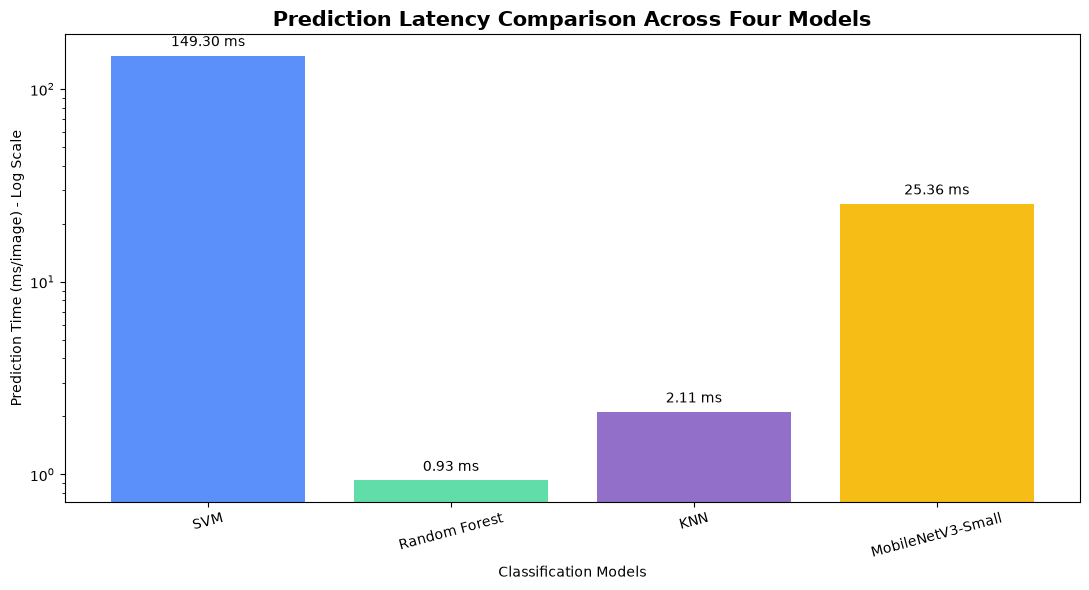

Four-model latency chart saved successfully!


In [49]:
#Final prediction latency comparison

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Add MobileNetV3 latency to the combined table
combined_results.loc[
    combined_results["Model"] == "MobileNetV3-Small",
    "Prediction Time (seconds)"
] = mobilenet_inference_time

combined_results.loc[
    combined_results["Model"] == "MobileNetV3-Small",
    "Prediction Time (ms/image)"
] = mobilenet_ms_per_image

# Save updated comparison
report_dir = Path(
    r"D:\dsc_1\ML\AgriCropDisease_Research_Project\reports"
)

combined_results.to_csv(
    report_dir / "four_model_comparison.csv",
    index=False
)

print("UPDATED FOUR-MODEL COMPARISON")
display(combined_results.round(4))

# Prediction latency chart
figure_dir = Path(
    r"D:\dsc_1\ML\AgriCropDisease_Research_Project\figures"
)

plt.figure(figsize=(11, 6))

latency_data = combined_results[
    "Prediction Time (ms/image)"
]

bars = plt.bar(
    combined_results["Model"],
    latency_data,
    color=["#5B8FF9", "#61DDAA", "#9270CA", "#F6BD16"]
)

plt.yscale("log")

plt.title(
    "Prediction Latency Comparison Across Four Models",
    fontsize=15,
    fontweight="bold"
)

plt.ylabel("Prediction Time (ms/image) - Log Scale")
plt.xlabel("Classification Models")
plt.xticks(rotation=15)

for bar, value in zip(bars, latency_data):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value * 1.12,
        f"{value:.2f} ms",
        ha="center",
        fontsize=10
    )

plt.tight_layout()

plt.savefig(
    figure_dir / "four_model_prediction_latency.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Four-model latency chart saved successfully!")



In [50]:
#Load and prepare the trained model

import torch
import torch.nn as nn
import numpy as np
import ipywidgets as widgets

from PIL import Image
from torchvision import models
from IPython.display import display, clear_output

# Restore trained model if not already available
if "mobilenet_model" not in globals():

    mobilenet_model = models.mobilenet_v3_small(weights=None)

    in_features = mobilenet_model.classifier[-1].in_features

    mobilenet_model.classifier[-1] = nn.Linear(
        in_features, len(class_names)
    )

    mobilenet_model.load_state_dict(checkpoint["model_state"])

mobilenet_model = mobilenet_model.to(device)
mobilenet_model.eval()

# Use exactly the same preprocessing as training
image_transform = train_ds.transform

print("Crop Disease Identification Model Ready!")
print("Architecture: MobileNetV3-Small")
print("Disease classes:", len(class_names))
print("Image size:", IMG_SIZE)
print("Device:", device)


Crop Disease Identification Model Ready!
Architecture: MobileNetV3-Small
Disease classes: 15
Image size: 224
Device: cpu


In [53]:

# ============================================================
# COMPLETE CROP DISEASE IDENTIFICATION AND INFORMATION RETRIEVAL
# MobileNetV3-Small + TF-IDF + Cosine Similarity
# ============================================================

import torch
import torch.nn as nn
import numpy as np
import ipywidgets as widgets
import pandas as pd
import io

from PIL import Image
from torchvision import models
from IPython.display import display, clear_output, HTML

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# ============================================================
# 1. LOAD TRAINED MODEL
# ============================================================

if "mobilenet_model" not in globals():

    mobilenet_model = models.mobilenet_v3_small(weights=None)

    in_features = mobilenet_model.classifier[-1].in_features

    mobilenet_model.classifier[-1] = nn.Linear(
        in_features, len(class_names)
    )

    mobilenet_model.load_state_dict(checkpoint["model_state"])

mobilenet_model = mobilenet_model.to(device)
mobilenet_model.eval()

image_transform = train_ds.transform

print("MobileNetV3-Small model loaded successfully!")


# ============================================================
# 2. DISEASE KNOWLEDGE BASE
# ============================================================

knowledge_base = [

    {
        "crop": "Tomato",
        "disease": "Tomato Early Blight",
        "symptoms": "Brown circular spots with concentric rings on older leaves.",
        "management": "Remove infected leaves, avoid overhead irrigation, maintain proper spacing and use recommended fungicides when necessary.",
        "source": "University of Minnesota Extension"
    },

    {
        "crop": "Tomato",
        "disease": "Tomato Late Blight",
        "symptoms": "Water-soaked lesions, dark brown leaf patches and white fungal growth under humid conditions.",
        "management": "Remove infected plant material, avoid wet foliage and use locally recommended disease management practices.",
        "source": "Cornell University"
    },

    {
        "crop": "Tomato",
        "disease": "Tomato Bacterial Leaf Spot",
        "symptoms": "Small dark water-soaked spots on leaves, sometimes surrounded by yellow areas.",
        "management": "Use disease-free seeds, avoid handling wet plants and remove infected plant debris.",
        "source": "University Extension Plant Pathology Resources"
    },

    {
        "crop": "Potato",
        "disease": "Potato Late Blight",
        "symptoms": "Dark water-soaked lesions on leaves and white fungal growth under humid conditions.",
        "management": "Use healthy seed tubers, remove infected plants and follow locally recommended fungicide practices.",
        "source": "Cornell University"
    },

    {
        "crop": "Potato",
        "disease": "Potato Early Blight",
        "symptoms": "Dark brown lesions with concentric rings, often on older leaves.",
        "management": "Maintain plant health, rotate crops, remove infected debris and use recommended disease management practices.",
        "source": "University Extension Plant Pathology Resources"
    }

]

# ============================================================
# 3. PREPARE TF-IDF RETRIEVAL MODEL
# ============================================================

documents = []

for record in knowledge_base:

    text = (
        record["crop"] + " " +
        record["disease"] + " " +
        record["symptoms"] + " " +
        record["management"]
    )

    documents.append(text)

vectorizer = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2)
)

tfidf_matrix = vectorizer.fit_transform(documents)

print("Disease knowledge base prepared!")
print("Total knowledge records:", len(knowledge_base))


# ============================================================
# 4. IMAGE CLASSIFICATION FUNCTION
# ============================================================

def predict_crop_disease(image):

    image_tensor = image_transform(image).unsqueeze(0).to(device)

    with torch.no_grad():

        outputs = mobilenet_model(image_tensor)

        probabilities = torch.softmax(outputs, dim=1)

    top_probabilities, top_indices = torch.topk(
        probabilities,
        k=min(5, len(class_names)),
        dim=1
    )

    results = []

    for probability, index in zip(
        top_probabilities[0],
        top_indices[0]
    ):

        results.append({
            "Disease": class_names[index.item()],
            "Confidence": round(
                probability.item() * 100, 2
            )
        })

    return results


# ============================================================
# 5. DISEASE INFORMATION RETRIEVAL FUNCTION
# ============================================================

def retrieve_disease_information(query):

    query_vector = vectorizer.transform([query])

    similarity_scores = cosine_similarity(
        query_vector,
        tfidf_matrix
    ).flatten()

    top_indices = np.argsort(
        similarity_scores
    )[::-1][:3]

    results = []

    for index in top_indices:

        if similarity_scores[index] > 0:

            results.append({
                "Disease": knowledge_base[index]["disease"],
                "Symptoms": knowledge_base[index]["symptoms"],
                "Management": knowledge_base[index]["management"],
                "Source": knowledge_base[index]["source"],
                "Similarity": round(
                    float(similarity_scores[index]), 4
                )
            })

    return results


# ============================================================
# 6. CREATE INTERACTIVE INTERFACE
# ============================================================

upload_widget = widgets.FileUpload(
    accept="image/*",
    multiple=False,
    description="Upload Leaf Image"
)

query_widget = widgets.Text(
    placeholder="Example: tomato early blight symptoms and management",
    description="Disease Query:",
    layout=widgets.Layout(width="90%")
)

predict_button = widgets.Button(
    description="Identify Disease",
    button_style="success",
    icon="search"
)

retrieve_button = widgets.Button(
    description="Retrieve Information",
    button_style="info",
    icon="book"
)

output_widget = widgets.Output()


# ============================================================
# 7. IMAGE UPLOAD AND PREDICTION
# ============================================================

def handle_prediction(button):

    with output_widget:

        clear_output(wait=True)

        if not upload_widget.value:

            print("Please upload a leaf image first!")
            return

        uploaded_file = upload_widget.value

        if isinstance(uploaded_file, dict):

            file_info = next(
                iter(uploaded_file.values())
            )

        else:

            file_info = uploaded_file[0]

        image = Image.open(
            io.BytesIO(file_info["content"])
        ).convert("RGB")

        print("UPLOADED CROP IMAGE")
        display(image)

        results = predict_crop_disease(image)

        print("\n" + "=" * 55)
        print("CROP DISEASE CLASSIFICATION RESULTS")
        print("=" * 55)

        print("\nPredicted Disease:",
              results[0]["Disease"])

        print("Prediction Confidence:",
              str(results[0]["Confidence"]) + "%")

        print("\nTOP 5 PREDICTIONS")

        for i, result in enumerate(results, start=1):

            print(
                f"{i}. {result['Disease']} - "
                f"{result['Confidence']}%"
            )


# ============================================================
# 8. DISEASE INFORMATION RETRIEVAL
# ============================================================

def handle_retrieval(button):

    with output_widget:

        clear_output(wait=True)

        query = query_widget.value.strip()

        if not query:

            print("Please enter a disease-related query!")
            return

        results = retrieve_disease_information(query)

        print("=" * 55)
        print("DISEASE INFORMATION RETRIEVAL")
        print("=" * 55)

        print("\nSearch Query:", query)

        if not results:

            print("\nNo matching information found.")
            return

        for i, result in enumerate(results, start=1):

            print("\nRESULT", i)
            print("-" * 45)

            print("Disease:", result["Disease"])
            print("Symptoms:", result["Symptoms"])
            print("Management:", result["Management"])
            print("Source:", result["Source"])

            print(
                "Cosine Similarity:",
                result["Similarity"]
            )


# ============================================================
# 9. CONNECT BUTTONS
# ============================================================

predict_button.on_click(handle_prediction)

retrieve_button.on_click(handle_retrieval)


# ============================================================
# 10. DISPLAY COMPLETE APPLICATION
# ============================================================

print("\n" + "=" * 60)
print("AGR/CROP DISEASE IDENTIFICATION SYSTEM")
print("=" * 60)

print("\nSTEP 1: Upload a crop leaf image")
display(upload_widget)

print("\nSTEP 2: Identify the disease")
display(predict_button)

print("\nSTEP 3: Search for disease information")
display(query_widget)
display(retrieve_button)

print("\nAPPLICATION OUTPUT")
display(output_widget)

print("\nSYSTEM READY!")
print("Image classification and disease retrieval are available.")


MobileNetV3-Small model loaded successfully!
Disease knowledge base prepared!
Total knowledge records: 5

AGR/CROP DISEASE IDENTIFICATION SYSTEM

STEP 1: Upload a crop leaf image


FileUpload(value=(), accept='image/*', description='Upload Leaf Image')


STEP 2: Identify the disease


Button(button_style='success', description='Identify Disease', icon='search', style=ButtonStyle())


STEP 3: Search for disease information


Text(value='', description='Disease Query:', layout=Layout(width='90%'), placeholder='Example: tomato early bl…

Button(button_style='info', description='Retrieve Information', icon='book', style=ButtonStyle())


APPLICATION OUTPUT


Output()


SYSTEM READY!
Image classification and disease retrieval are available.


## 13. Research reporting checklist

Before reporting results in a paper:
- Record the dataset source/version, class counts, split proportions, random seed, and exact training settings.
- Check for exact and near-duplicate images across splits and datasets before final experiments. A stratified random split alone does not prove duplicate-free separation.
- Report accuracy, macro precision, macro recall, macro F1, per-class metrics, and the confusion matrix.
- Do not claim PDR/Cassava external performance until a compatible label mapping and separate evaluation pipeline are implemented.
- Report the CPU/GPU, Python, PyTorch, image size, batch size, epochs, and pretrained weights.
- Grad-CAM is an explanation visualization, not proof that a model is correct.
- Evaluate RAG retrieval separately for relevance, source validity, and citation correctness after adding verified sources.
- Do not describe the current notebook as full multimodal fusion: it combines an image classifier with a separate text-retrieval component.